In [1]:
# for auto-reloading external modules
%load_ext autoreload
%autoreload 2

import numpy as np
from matplotlib import pyplot as plt
from matplotlib.collections import LineCollection
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from scipy.io import loadmat
import glob
import h5py
from scipy.stats import pearsonr
import torch
from torch import nn
from sklearn.metrics import roc_curve, precision_recall_curve, auc
from sklearn.metrics.pairwise import cosine_similarity
from scipy.stats import binned_statistic
import pandas as pd
import pickle

import sys
# sys.path.append('/mnt/scratch09/yongrong/projects/bat-intelligence/src/digitalbat')
sys.path.append('/home/adam/digitalbat')
from digitalbat.datasets.data import bat_data_loader
from digitalbat.models.former import Bat_Transformer
from digitalbat.models.glm import Bat_GLM
from digitalbat.models.layers import ELU1, TransformerEncoderRoPE
from digitalbat.training.trainer import bat_former_trainer
from digitalbat.utility.utils import auprc_per_unit, corr, interpolate_signal_with_nans, lowpass_filter, \
                                    corr, poisson_fraction_deviance_explained, poisson_fde_population, generate_2d_rate_map
from digitalbat.utility.utils import set_random_state, plot_2d_rate_map, plot_2d_trajectory_response, plot_2d_trajectory_response_multiple, \
                                    plot_3d_trajectory, resample_response, nearest_neighbor_score, OrthogonalityPermutationTest
from digitalbat.datasets.data import Data_Prep_for_Raw, bat_data_loader
from digitalbat.utility.interpreter import Saliency, PermutationImportance, ActivationMaximization, ShapAnalysis, Gradient_Bat_Transformer # IntegGradi
from digitalbat.utility.TrajectoryRF import Generate_Synthetic_Trajecories, Time_Resolved_TRF, Time_Resolved_Phase, Trajectory_Level_TRF

/home/adam/miniconda3/envs/cpu/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
seed = 1
set_random_state(seed)

device = 'cpu'

# Dataloader

In [3]:
# recorded data
data_config = dict(
    use_speed_head_dir = False, # False
    use_IMU_flag = False,  # False
    use_click_flag = False, # False
    use_LFP_flag = False,  # False
    use_ripple_flag = False,
    only_flight_flag = True,  # True
    no_3d_location = False, # False
    spike_count_flag = True,
    bin_width = 0.10, # 0.10, in seconds
    split_flights_for_train = 'random', # the way to split flight paths for train + valid + test; either 'manual' or 'random'
    type_train_num = 1,  # 1; for splitting flight clustering data
    type_valid_num = 1,  # 1; for splitting flight clustering data
    special_id_count_thresh = 3,  # 3; for splitting flight clustering data
    only_use_special_id_4train_flag = False,  # False
    shuffle_flag = True, # False; shuffle the training data
    time_shuffle_for_trajecotry_flag = False,
    simulate_place_cell_flag = False, # False
    split_each_trajectory_flag = True,  # True
    window_size = None, # 20, None; for splitting each trajectory into multiple samples
    stride_train = None, # 20, None; splitting each trajectory into multiple samples, for training data
    stride_test = None, # 20, None; splitting each trajectory into multiple samples, for test data
    batch_size_train = None, # None;
    batch_size_test = None, # None;
    session_names = [
        'Dataset_3_14543_240419',
        'Dataset_3_14543_240420',
        'Dataset_3_14543_240421',
        'Dataset_3_29959_240402',
        'Dataset_3_29959_240403',
        'Dataset_3_29959_240404',
        'Dataset_2_14445_231208',
        'Dataset_2_14445_231209', # only 9 flight trajectory types
        'Dataset_1_32622_231009',
        'Dataset_1_32622_231010',  # only ~50 units
    ],
)
dataloaders, behavior_dim, unit_num_dict, meta_info_dict = bat_data_loader(**data_config)

dataloaders, behavior_dim, unit_num_dict

({'train': {'Dataset_3_14543_240419': <torch.utils.data.dataloader.DataLoader at 0x708b4136fa10>,
   'Dataset_3_14543_240420': <torch.utils.data.dataloader.DataLoader at 0x708b4134f190>,
   'Dataset_3_14543_240421': <torch.utils.data.dataloader.DataLoader at 0x708b41356450>,
   'Dataset_3_29959_240402': <torch.utils.data.dataloader.DataLoader at 0x708b4136d390>,
   'Dataset_3_29959_240403': <torch.utils.data.dataloader.DataLoader at 0x708b4136fbd0>,
   'Dataset_3_29959_240404': <torch.utils.data.dataloader.DataLoader at 0x708b41366310>,
   'Dataset_2_14445_231208': <torch.utils.data.dataloader.DataLoader at 0x708b4134fe50>,
   'Dataset_2_14445_231209': <torch.utils.data.dataloader.DataLoader at 0x708b413646d0>,
   'Dataset_1_32622_231009': <torch.utils.data.dataloader.DataLoader at 0x708b4a64fe50>,
   'Dataset_1_32622_231010': <torch.utils.data.dataloader.DataLoader at 0x708b413677d0>},
  'valid': {'Dataset_3_14543_240419': <torch.utils.data.dataloader.DataLoader at 0x708b4136ddd0>,
  

In [4]:
for session_name, session_data in dataloaders['train'].items():
    print(session_name, session_data)
    for batch_id, batch in enumerate(session_data):
        if not data_config['split_each_trajectory_flag']:
            print(batch[0].shape, batch[1].shape) # (N, behavior_feature), (N, spiking_unit_number)
        else:
            # behavior (N, window_size, behavior_feature), spike (N, window_size, spiking_unit_number), mask (N, window_size)
            print(batch[0].shape, batch[1].shape, batch[2].shape, np.sum(batch[2].detach().cpu().numpy()*1.0)) 

Dataset_3_14543_240419 <torch.utils.data.dataloader.DataLoader object at 0x708b4136fa10>
torch.Size([25, 119, 3]) torch.Size([25, 119, 289]) torch.Size([25, 119]) 755.0
Dataset_3_14543_240420 <torch.utils.data.dataloader.DataLoader object at 0x708b4134f190>
torch.Size([95, 97, 3]) torch.Size([95, 97, 126]) torch.Size([95, 97]) 2380.0
Dataset_3_14543_240421 <torch.utils.data.dataloader.DataLoader object at 0x708b41356450>
torch.Size([78, 61, 3]) torch.Size([78, 61, 100]) torch.Size([78, 61]) 1964.0
Dataset_3_29959_240402 <torch.utils.data.dataloader.DataLoader object at 0x708b4136d390>
torch.Size([107, 81, 3]) torch.Size([107, 81, 317]) torch.Size([107, 81]) 3301.0
Dataset_3_29959_240403 <torch.utils.data.dataloader.DataLoader object at 0x708b4136fbd0>
torch.Size([91, 73, 3]) torch.Size([91, 73, 191]) torch.Size([91, 73]) 2493.0
Dataset_3_29959_240404 <torch.utils.data.dataloader.DataLoader object at 0x708b41366310>
torch.Size([55, 65, 3]) torch.Size([55, 65, 190]) torch.Size([55, 65]) 

In [5]:
tier = 'train'
session_name = list(dataloaders[tier].keys())[0]
for ii, batch in enumerate(dataloaders[tier][session_name]):
    if not data_config['split_each_trajectory_flag']:
        print(batch[0].shape, batch[1].shape) 
    else:
        print(batch[0].shape, batch[1].shape, batch[2].shape) # torch.Size([61, 20, 3]) torch.Size([61, 20, 289]) torch.Size([61, 20])
# get the elements at real timesteps
tempbeha = batch[0].detach().cpu().numpy()
tempspik = batch[1].detach().cpu().numpy()
tempmask = batch[2].detach().cpu().numpy()
print(tempbeha.shape, tempspik.shape) # (61, 20, 3) (61, 20, 289)
tempbeha = tempbeha[tempmask ==1]
tempspik = tempspik[tempmask ==1]
print(tempbeha.shape, tempspik.shape) # (981, 3) (981, 289)

torch.Size([25, 119, 3]) torch.Size([25, 119, 289]) torch.Size([25, 119])
(25, 119, 3) (25, 119, 289)
(755, 3) (755, 289)


In [6]:
batch._fields, batch.flight_path_index, batch.flight_type_index

(('behavior', 'spike', 'mask', 'flight_path_index', 'flight_type_index'),
 tensor([26., 18., 23.,  6.,  8., 28., 19.,  9., 21.,  2.,  7.,  3., 15., 36.,
         14., 22., 16., 27., 13., 34., 32., 31., 30.,  0., 25.]),
 tensor([10.,  9.,  9.,  3.,  3., 12.,  9.,  3.,  9.,  2.,  3.,  3.,  7., 21.,
          6.,  9.,  8., 11.,  5., 19., 17., 16., 15.,  1., 10.]))

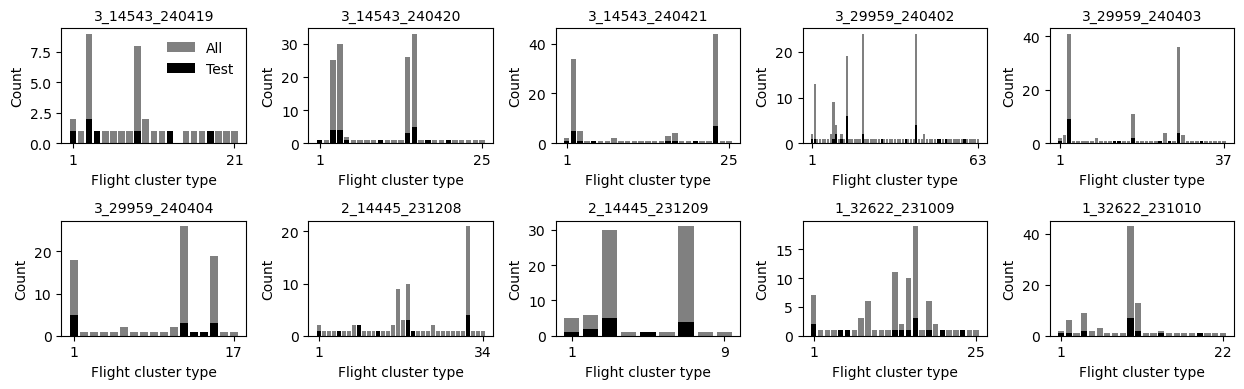

In [7]:
# summarize the flight cluster type distribution
session_names = list(dataloaders['test'].keys())
ncols = 5
nrows = len(session_names) // ncols
fig, axes = plt.subplots(nrows=nrows, ncols=ncols,figsize=(ncols*2.5,nrows*2))
for ii in range(nrows):
    for jj in range(ncols):
        session_name = list(dataloaders['test'].keys()) [ii * ncols + jj]
        flight_type_train = dataloaders['train'][session_name].dataset.flight_type_index.detach().cpu().numpy()
        flight_type_valid = dataloaders['valid'][session_name].dataset.flight_type_index.detach().cpu().numpy()
        flight_type_test = dataloaders['test'][session_name].dataset.flight_type_index.detach().cpu().numpy()
        flight_type = np.concatenate((flight_type_train, flight_type_valid, flight_type_test))
        unique_vals, counts = np.unique(flight_type, return_counts=True)
        unique_vals_test, counts_test = np.unique(flight_type_test, return_counts=True)
        axes[ii,jj].bar(unique_vals, counts, color='gray', label='All')
        axes[ii,jj].bar(unique_vals_test, counts_test, color='k', label='Test')
        axes[ii,jj].set_xticks([1, unique_vals.max()])
        axes[ii,jj].set_xlabel("Flight cluster type")
        axes[ii,jj].set_ylabel("Count")
        axes[ii,jj].set_title(f'{session_name[8:]}', fontsize=10)
axes[0,0].legend(loc='best',frameon=False)
plt.tight_layout()

# Transformer model

In [8]:
model_config = dict(
    input_dim = behavior_dim,
    output_dim_dict=unit_num_dict, 
    # place
    use_place_as_input=False, # add spatial basis
    spatial_centers_sigma_dict=meta_info_dict['spatial_centers_sigma'],
    latent_dim_place = 32,
    # trajectory
    use_trajectory_as_input=True,
    latent_dim = 32, # 256
    ff_dim = 32, # 256
    num_heads = 4, # 4
    num_layers = 1, # 1
    dropout_prob = 0.3, # 0.7
    #
    # use_low_rank = True, # low rank matrix multiplication
    # use_low_rank_readout = True, # low rank for readouts
    # low_rank_r = 4, # 4
    final_activation=ELU1(), # nn.Identity(),
)
bat_former = Bat_Transformer(**model_config)

bat_former

Bat_Transformer(
  (embed_traj): Linear(in_features=3, out_features=32, bias=True)
  (embed_traj_dropout): Dropout(p=0.1, inplace=False)
  (layers): ModuleList(
    (0): TransformerEncoderRoPE(
      (attention): MultiheadAttentionRoPE(
        (W_q): Linear(in_features=32, out_features=32, bias=True)
        (W_k): Linear(in_features=32, out_features=32, bias=True)
        (W_v): Linear(in_features=32, out_features=32, bias=True)
        (W_o): Linear(in_features=32, out_features=32, bias=True)
      )
      (ff): Sequential(
        (0): Linear(in_features=32, out_features=32, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=32, out_features=32, bias=True)
      )
      (dropout): Dropout(p=0.3, inplace=False)
      (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
      (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
    )
  )
  (readouts): ModuleDict(
    (Dataset_3_14543_240419): Sequential(
      (0): Linear(in_features=32

# Training

In [ ]:
trainer_config = dict(
    model = bat_former,
    dataloaders = dataloaders,
    device = device,
    is_causal = False,  # False
    is_bigbird = False,  # False
    attention_window_size = 9,  # 3; bigbird style sparse attention
    num_global = 2,  # 2; bigbird style sparse attention
    n_epochs = 1000,  # 500
    # use_cosine_scheduler = True,
    lr = 0.01,  # 0.001
    loss_fn = nn.PoissonNLLLoss(log_input=False),
    valid_fn = lambda y_true, y_pred: corr(y_true, y_pred, axis=0),
    valid_stat = 'mean', # 'mean', 'median'
    save_model = True,  # False
    # f'./out/bat_former_data_random_trajectory_input_seed_{seed}.pth', # real data + trajectory input
    # f'./out/bat_former_data_random_dual_input_seed_{seed}.pth', # real data + dual-input model
    # f'./out/bat_former_data_simulate_dual_input_seed_{seed}.pth', # simulate place cell + dual-input model
    # f'./out/bat_former_data_random_seed_{seed}.pth' # f'./out/test.pth'
    model_name = f'./out/bat_former_data_random_trajectory_input_seed_{seed}.pth', 
)

# best_acc, best_weights, acc_vals = bat_former_trainer(**trainer_config)
# fig, axes = plt.subplots(nrows=1, ncols=1,figsize=(2.5,2))
# axes.plot(acc_vals, )
# axes.set_title(f'{best_acc:.4f}')
# axes.set_xlabel('Epoch')
# axes.set_ylabel('Correlation')

# Evaluation

In [ ]:
# f'./out/bat_former_data_random_trajectory_input_seed_1.pth' # real data + trajectory input
# f'./out/bat_former_data_random_dual_input_seed_1.pth' # real data + dual-input model
# f'./out/bat_former_data_simulate_dual_input_seed_1.pth', # simulate place cell + dual-input model
# './out/bat_former_data_random_seed_1.pth' # f'./out/test.pth'
model_name = f'./out/bat_former_data_random_trajectory_input_seed_1.pth'

## Correlation

In [ ]:
# evaluation on test data
valid_fn = lambda y_true, y_pred: corr(y_true, y_pred, axis=0)
# valid_fn = lambda y_true, y_pred: poisson_fde_population(y_true, y_pred)
bat_former.load_state_dict(torch.load(model_name, map_location=device))
# bat_former.load_state_dict(best_weights)
bat_former = bat_former.to(device)
bat_former.eval()
corr_dict = {} # a dictionary of score arrays (for each unit) for different sessions
for session_name, session_data in dataloaders['test'].items():
    # print(session_name, session_data)
    y_val_np_list, y_pred_np_list = [], []
    for batch_id, batch in enumerate(session_data):
        X_val = batch[0].to(device)
        y_val = batch[1].to(device)
        mask_val = batch[2].to(device)
        y_pred = bat_former(
            session_name, 
            X_val, 
            mask_val, 
            is_causal=trainer_config['is_causal'], 
            is_bigbird=trainer_config['is_bigbird'], 
            attention_window_size=trainer_config['attention_window_size'],
            num_global=trainer_config['num_global'],
        )
        y_val_np = y_val.detach()[mask_val == 1.0].cpu().numpy() 
        y_pred_np = y_pred.detach()[mask_val == 1.0].cpu().numpy()
        y_val_np_list.append(y_val_np)
        y_pred_np_list.append(y_pred_np)
    y_val_np = np.vstack(y_val_np_list)
    y_pred_np = np.vstack(y_pred_np_list)
    temp_scores = valid_fn(y_val_np, y_pred_np) # an array of scores for spiking units in one batch data within one session of data
    corr_dict[session_name] = temp_scores

Mean of Corr: 0.2547943890094757


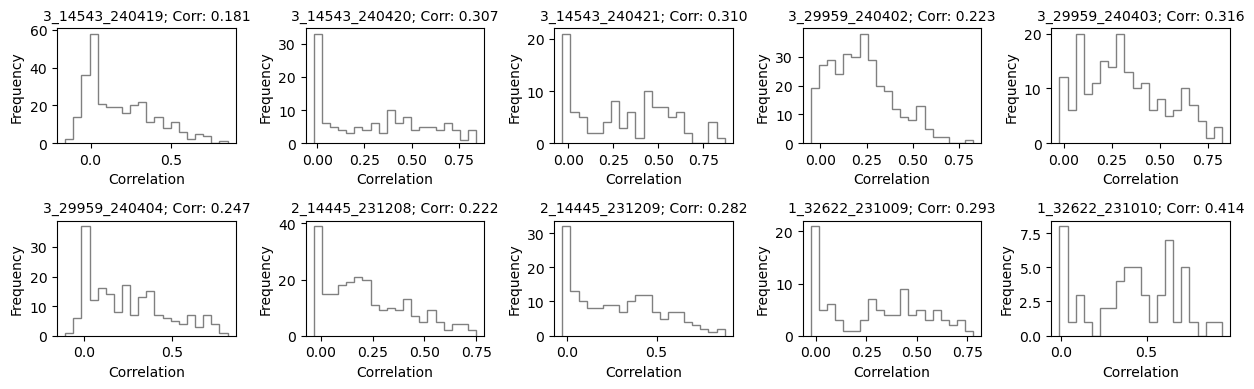

In [17]:
print(f"Mean of Corr: {np.nanmean(np.hstack([corr_dict[session_name] for session_name in list(dataloaders['test'].keys())]))}")
ncols = 5
nrows = len(list(dataloaders['test'].keys())) // ncols
fig, axes = plt.subplots(nrows=nrows, ncols=ncols,figsize=(ncols*2.5,nrows*2))
for ii in range(nrows):
    for jj in range(ncols):
        session_name = list(dataloaders['test'].keys()) [ii * ncols + jj]
        data = np.copy(corr_dict[session_name])
        hist_max = np.max(data)
        hist_min = np.min(data)
        weights = np.ones_like(data) # /float(len(data))
        axes[ii,jj].hist(data, bins=20, color='gray',range=[hist_min,hist_max],weights=weights,alpha=1,histtype='step')
        axes[ii,jj].set_xlabel('Correlation')
        axes[ii,jj].set_ylabel('Frequency')
        axes[ii,jj].set_title(f'{session_name[8:]}; Corr: {np.nanmean(data):.3f}', fontsize=10)
plt.tight_layout()

## Out-of-domain Corr

In [20]:
# ood score (correlation)
valid_fn = lambda y_true, y_pred: corr(y_true, y_pred, axis=0)
# valid_fn = lambda y_true, y_pred: poisson_fde_population(y_true, y_pred)
bat_former.load_state_dict(torch.load(model_name, map_location=device))
# bat_former.load_state_dict(best_weights)
bat_former = bat_former.to(device)
bat_former.eval()
corr_ood_dict = {} # a dictionary of score arrays (for each unit) for different sessions
for session_name, session_data in dataloaders['test'].items():
    # print(session_name, session_data)
    target_types = np.array(meta_info_dict['flight_type_test_ood'][session_name], dtype=int) # data type: int
    if target_types.size == 0:
        corr_ood_dict[session_name] = np.zeros((1,))
        print(f'{session_name} has no OOD flights')
        continue
    y_val_np_list, y_pred_np_list = [], []
    for batch_id, batch in enumerate(session_data):
        X_val = batch[0].to(device) # (torch.Size([15, 70, 3]),
        y_val = batch[1].to(device) # torch.Size([15, 70, 54])
        mask_val = batch[2].to(device) # torch.Size([15, 70]))
        y_pred = bat_former(
            session_name, 
            X_val, 
            mask_val, 
            is_causal=trainer_config['is_causal'], 
            is_bigbird=trainer_config['is_bigbird'], 
            attention_window_size=trainer_config['attention_window_size'],
            num_global=trainer_config['num_global'],
        )        
        flight_type_index = batch.flight_type_index.detach().cpu().numpy().astype(int) # data type: int
        # Find indices where flight_type_index ∈ target_inds
        target_indices = np.where( np.isin(flight_type_index, target_types) )[0]
        mask_val = mask_val.detach().cpu().numpy()[target_indices]        
        y_val_np = y_val.detach().cpu().numpy()[target_indices][mask_val == 1.0]
        y_pred_np = y_pred.detach().cpu().numpy()[target_indices][mask_val == 1.0]
        y_val_np_list.append(y_val_np)
        y_pred_np_list.append(y_pred_np)
    y_val_np = np.vstack(y_val_np_list)
    y_pred_np = np.vstack(y_pred_np_list)
    temp_scores = valid_fn(y_val_np, y_pred_np) # an array of scores for spiking units in one batch data within one session of data
    corr_ood_dict[session_name] = temp_scores

Mean of Corr for out-of-domain flights: 0.14137396216392517


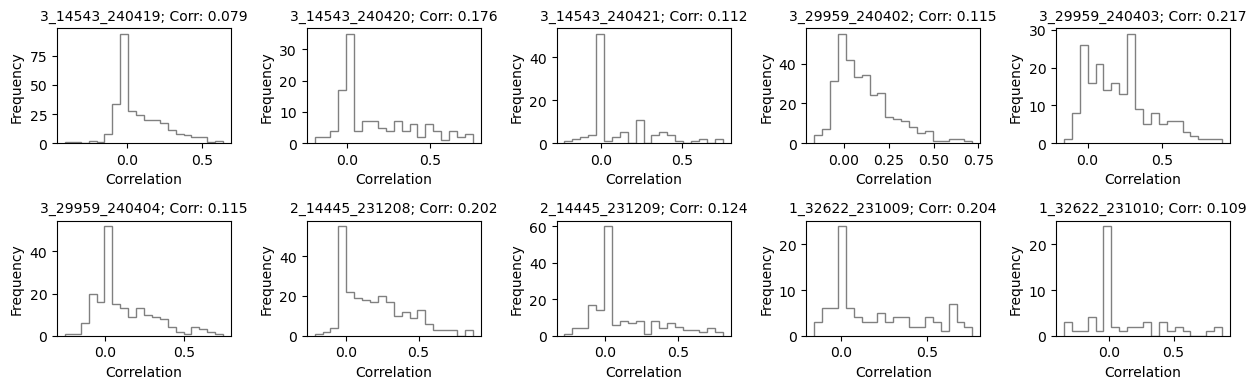

In [21]:
print(f"Mean of Corr for out-of-domain flights: {np.nanmean(np.hstack([corr_ood_dict[session_name] for session_name in list(dataloaders['test'].keys())]))}")
ncols = 5
nrows = len(list(dataloaders['test'].keys())) // ncols
fig, axes = plt.subplots(nrows=nrows, ncols=ncols,figsize=(ncols*2.5,nrows*2))
for ii in range(nrows):
    for jj in range(ncols):
        session_name = list(dataloaders['test'].keys()) [ii * ncols + jj]
        data = np.copy(corr_ood_dict[session_name])
        hist_max = np.max(data)
        hist_min = np.min(data)
        weights = np.ones_like(data) # /float(len(data))
        axes[ii,jj].hist(data, bins=20, color='gray',range=[hist_min,hist_max],weights=weights,alpha=1,histtype='step')
        axes[ii,jj].set_xlabel('Correlation')
        axes[ii,jj].set_ylabel('Frequency')
        axes[ii,jj].set_title(f'{session_name[8:]}; Corr: {np.nanmean(data):.3f}', fontsize=10)
plt.tight_layout()

## In-domain corr. and nearest neighbor analysis

In [22]:
# indomain score (correlation)
valid_fn = lambda y_true, y_pred: corr(y_true, y_pred, axis=0)
# valid_fn = lambda y_true, y_pred: poisson_fde_population(y_true, y_pred)
bat_former.load_state_dict(torch.load(model_name, map_location=device))
# bat_former.load_state_dict(best_weights)
bat_former = bat_former.to(device)
bat_former.eval()
corr_indomain_dict = {} # a dictionary of score arrays (for each unit) for different sessions
for session_name, session_data in dataloaders['test'].items():
    # print(session_name, session_data)
    target_types = np.array(meta_info_dict['flight_type_test_indomain'][session_name], dtype=int) # data type: int
    y_val_np_list, y_pred_np_list = [], []
    for batch_id, batch in enumerate(session_data):
        X_val = batch[0].to(device) # (torch.Size([15, 70, 3]),
        y_val = batch[1].to(device) # torch.Size([15, 70, 54])
        mask_val = batch[2].to(device) # torch.Size([15, 70]))
        y_pred = bat_former(
            session_name, 
            X_val, 
            mask_val, 
            is_causal=trainer_config['is_causal'], 
            is_bigbird=trainer_config['is_bigbird'], 
            attention_window_size=trainer_config['attention_window_size'],
            num_global=trainer_config['num_global'],
        )        
        flight_type_index = batch.flight_type_index.detach().cpu().numpy().astype(int) # data type: int
        # Find indices where flight_type_index ∈ target_inds
        target_indices = np.where( np.isin(flight_type_index, target_types) )[0]
        mask_val = mask_val.detach().cpu().numpy()[target_indices]        
        y_val_np = y_val.detach().cpu().numpy()[target_indices][mask_val == 1.0]
        y_pred_np = y_pred.detach().cpu().numpy()[target_indices][mask_val == 1.0]
        y_val_np_list.append(y_val_np)
        y_pred_np_list.append(y_pred_np)
    y_val_np = np.vstack(y_val_np_list)
    y_pred_np = np.vstack(y_pred_np_list) # shape: (425, 54)
    temp_scores = valid_fn(y_val_np, y_pred_np) # an array of scores for spiking units in one batch data within one session of data
    corr_indomain_dict[session_name] = temp_scores

Mean of Corr for in-domain flights: 0.2725926339626312


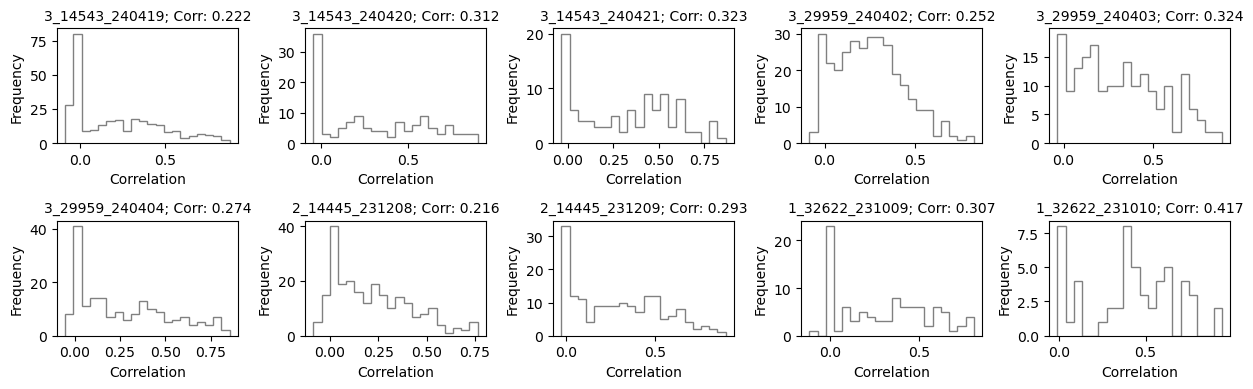

In [23]:
print(f"Mean of Corr for in-domain flights: {np.nanmean(np.hstack([corr_indomain_dict[session_name] for session_name in list(dataloaders['test'].keys())]))}")
ncols = 5
nrows = len(list(dataloaders['test'].keys())) // ncols
fig, axes = plt.subplots(nrows=nrows, ncols=ncols,figsize=(ncols*2.5,nrows*2))
for ii in range(nrows):
    for jj in range(ncols):
        session_name = list(dataloaders['test'].keys()) [ii * ncols + jj]
        data = np.copy(corr_indomain_dict[session_name])
        hist_max = np.max(data)
        hist_min = np.min(data)
        weights = np.ones_like(data) # /float(len(data))
        axes[ii,jj].hist(data, bins=20, color='gray',range=[hist_min,hist_max],weights=weights,alpha=1,histtype='step')
        axes[ii,jj].set_xlabel('Correlation')
        axes[ii,jj].set_ylabel('Frequency')
        axes[ii,jj].set_title(f'{session_name[8:]}; Corr: {np.nanmean(data):.3f}', fontsize=10)
plt.tight_layout()

## Fraction deviance explained

In [25]:
# evaluation on test data
# valid_fn = lambda y_true, y_pred: corr(y_true, y_pred, axis=0)
valid_fn = lambda y_true, y_pred: poisson_fde_population(y_true, y_pred)
bat_former.load_state_dict(torch.load(model_name, map_location=device))
# bat_former.load_state_dict(best_weights)
bat_former = bat_former.to(device)
bat_former.eval()
fde_dict = {} # a dictionary of score arrays (for each unit) for different sessions
for session_name, session_data in dataloaders['test'].items():
    # print(session_name, session_data)
    y_val_np_list, y_pred_np_list = [], []
    for batch_id, batch in enumerate(session_data):
        X_val = batch[0].to(device)
        y_val = batch[1].to(device)
        mask_val = batch[2].to(device)
        y_pred = bat_former(
            session_name, 
            X_val, 
            mask_val, 
            is_causal=trainer_config['is_causal'], 
            is_bigbird=trainer_config['is_bigbird'], 
            attention_window_size=trainer_config['attention_window_size'],
            num_global=trainer_config['num_global'],
        )
        y_val_np = y_val.detach()[mask_val == 1.0].cpu().numpy() # shape: (N, spiking_unit_number)
        y_pred_np = y_pred.detach()[mask_val == 1.0].cpu().numpy()
        # fdes = np.empty((y_val_np.shape[1]))
        # for ii in range(len(fdes)):
        #     fdes[ii] = poisson_fraction_deviance_explained(y_val_np[:,ii], y_pred_np[:,ii]) # an array of scores for spiking units in one batch data within one session of data
        y_val_np_list.append(y_val_np)
        y_pred_np_list.append(y_pred_np)
    y_val_np = np.vstack(y_val_np_list)
    y_pred_np = np.vstack(y_pred_np_list)
    fdes = valid_fn(y_val_np, y_pred_np) 
    fde_dict[session_name] = fdes

Median of FDE: 0.07447069883346558


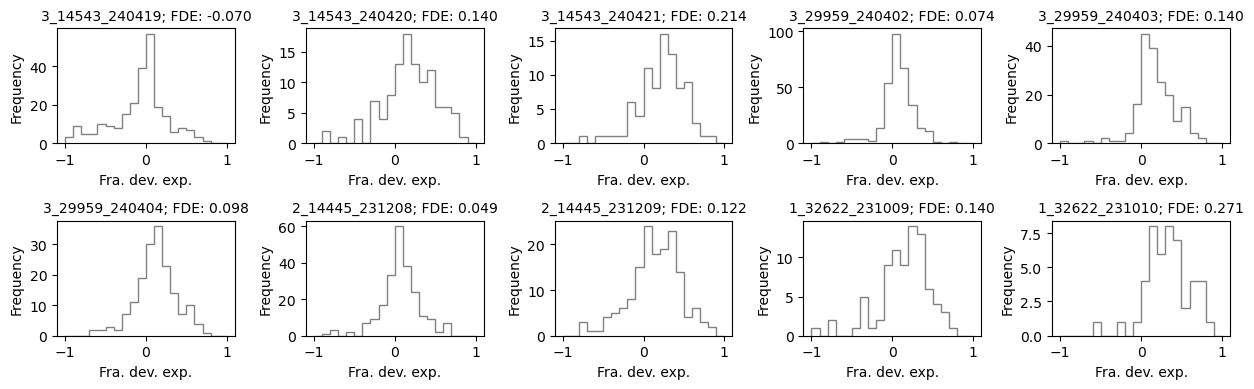

In [26]:
print(f"Median of FDE: {np.nanmedian(np.hstack([fde_dict[session_name] for session_name in list(dataloaders['test'].keys())]))}")
ncols = 5
nrows = len(list(dataloaders['test'].keys())) // ncols
fig, axes = plt.subplots(nrows=nrows, ncols=ncols,figsize=(ncols*2.5,nrows*2))
for ii in range(nrows):
    for jj in range(ncols):
        session_name = list(dataloaders['test'].keys()) [ii * ncols + jj]
        data = np.copy(fde_dict[session_name])
        hist_max = 1.0 # np.max(data)
        hist_min = -1.0 # np.min(data)
        weights = np.ones_like(data) # /float(len(data))
        axes[ii,jj].hist(data, bins=20, color='gray',range=[hist_min,hist_max],weights=weights,alpha=1,histtype='step')
        axes[ii,jj].set_xlabel('Fra. dev. exp.')
        axes[ii,jj].set_ylabel('Frequency')
        axes[ii,jj].set_title(f'{session_name[8:]}; FDE: {np.nanmedian(data):.3f}', fontsize=10)
plt.tight_layout()

## OOD FDE

In [27]:
# ood score 
# valid_fn = lambda y_true, y_pred: corr(y_true, y_pred, axis=0)
valid_fn = lambda y_true, y_pred: poisson_fde_population(y_true, y_pred)
bat_former.load_state_dict(torch.load(model_name, map_location=device))
# bat_former.load_state_dict(best_weights)
bat_former = bat_former.to(device)
bat_former.eval()
fde_ood_dict = {} # a dictionary of score arrays (for each unit) for different sessions
for session_name, session_data in dataloaders['test'].items():
    # print(session_name, session_data)
    target_types = np.array(meta_info_dict['flight_type_test_ood'][session_name], dtype=int) # data type: int
    if target_types.size == 0:
        fde_ood_dict[session_name] = np.zeros((1,))
        print(f'{session_name} has no OOD flights')
        continue
    y_val_np_list, y_pred_np_list = [], []
    for batch_id, batch in enumerate(session_data):
        X_val = batch[0].to(device) # (torch.Size([15, 70, 3]),
        y_val = batch[1].to(device) # torch.Size([15, 70, 54])
        mask_val = batch[2].to(device) # torch.Size([15, 70]))
        y_pred = bat_former(
            session_name, 
            X_val, 
            mask_val, 
            is_causal=trainer_config['is_causal'], 
            is_bigbird=trainer_config['is_bigbird'], 
            attention_window_size=trainer_config['attention_window_size'],
            num_global=trainer_config['num_global'],
        )        
        flight_type_index = batch.flight_type_index.detach().cpu().numpy().astype(int) # data type: int
        # Find indices where flight_type_index ∈ target_inds
        target_indices = np.where( np.isin(flight_type_index, target_types) )[0]
        mask_val = mask_val.detach().cpu().numpy()[target_indices]        
        y_val_np = y_val.detach().cpu().numpy()[target_indices][mask_val == 1.0]
        y_pred_np = y_pred.detach().cpu().numpy()[target_indices][mask_val == 1.0]
        y_val_np_list.append(y_val_np)
        y_pred_np_list.append(y_pred_np)
    y_val_np = np.vstack(y_val_np_list)
    y_pred_np = np.vstack(y_pred_np_list)
    temp_scores = valid_fn(y_val_np, y_pred_np) # an array of scores for spiking units in one batch data within one session of data
    fde_ood_dict[session_name] = temp_scores

Median of FDE for out-of-domain flights: -0.1087498664855957


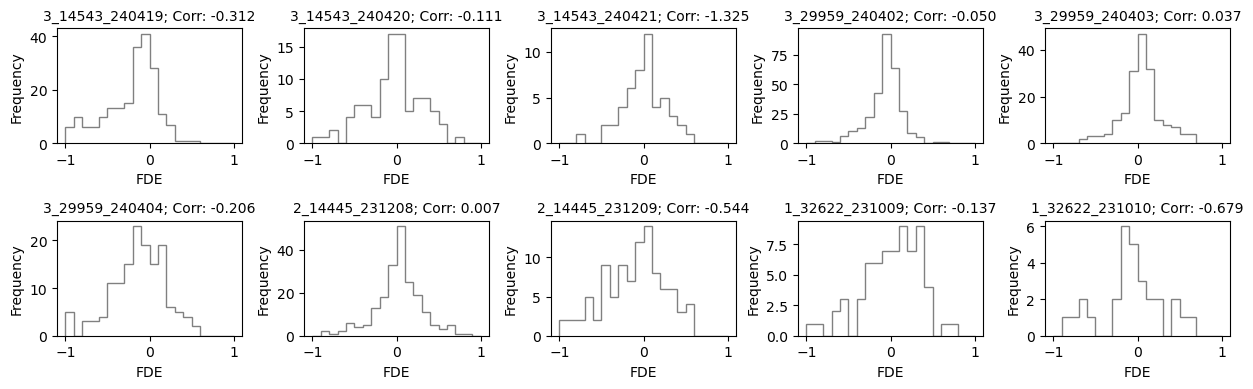

In [28]:
print(f"Median of FDE for out-of-domain flights: {np.nanmedian(np.hstack([fde_ood_dict[session_name] for session_name in list(dataloaders['test'].keys())]))}")
ncols = 5
nrows = len(list(dataloaders['test'].keys())) // ncols
fig, axes = plt.subplots(nrows=nrows, ncols=ncols,figsize=(ncols*2.5,nrows*2))
for ii in range(nrows):
    for jj in range(ncols):
        session_name = list(dataloaders['test'].keys()) [ii * ncols + jj]
        data = np.copy(fde_ood_dict[session_name])
        hist_max = 1.0 # np.max(data)
        hist_min = -1.0 # np.min(data)
        weights = np.ones_like(data) # /float(len(data))
        axes[ii,jj].hist(data, bins=20, color='gray',range=[hist_min,hist_max],weights=weights,alpha=1,histtype='step')
        axes[ii,jj].set_xlabel('FDE')
        axes[ii,jj].set_ylabel('Frequency')
        axes[ii,jj].set_title(f'{session_name[8:]}; Corr: {np.nanmedian(data):.3f}', fontsize=10)
plt.tight_layout()

## In-domain FDE and NN analysis

In [30]:
# indomain score (correlation)
# valid_fn = lambda y_true, y_pred: corr(y_true, y_pred, axis=0)
valid_fn = lambda y_true, y_pred: poisson_fde_population(y_true, y_pred)
bat_former.load_state_dict(torch.load(model_name, map_location=device))
# bat_former.load_state_dict(best_weights)
bat_former = bat_former.to(device)
bat_former.eval()
fde_indomain_dict = {} # a dictionary of score arrays (for each unit) for different sessions
for session_name, session_data in dataloaders['test'].items():
    # print(session_name, session_data)
    target_types = np.array(meta_info_dict['flight_type_test_indomain'][session_name], dtype=int) # data type: int
    y_val_np_list, y_pred_np_list = [], []
    for batch_id, batch in enumerate(session_data):
        X_val = batch[0].to(device) # (torch.Size([15, 70, 3]),
        y_val = batch[1].to(device) # torch.Size([15, 70, 54])
        mask_val = batch[2].to(device) # torch.Size([15, 70]))
        y_pred = bat_former(
            session_name, 
            X_val, 
            mask_val, 
            is_causal=trainer_config['is_causal'], 
            is_bigbird=trainer_config['is_bigbird'], 
            attention_window_size=trainer_config['attention_window_size'],
            num_global=trainer_config['num_global'],
        )        
        flight_type_index = batch.flight_type_index.detach().cpu().numpy().astype(int) # data type: int
        # Find indices where flight_type_index ∈ target_inds
        target_indices = np.where( np.isin(flight_type_index, target_types) )[0]
        mask_val = mask_val.detach().cpu().numpy()[target_indices]        
        y_val_np = y_val.detach().cpu().numpy()[target_indices][mask_val == 1.0]
        y_pred_np = y_pred.detach().cpu().numpy()[target_indices][mask_val == 1.0]
        y_val_np_list.append(y_val_np)
        y_pred_np_list.append(y_pred_np)
    y_val_np = np.vstack(y_val_np_list)
    y_pred_np = np.vstack(y_pred_np_list) # shape: (425, 54)
    temp_scores = valid_fn(y_val_np, y_pred_np) # an array of scores for spiking units in one batch data within one session of data
    fde_indomain_dict[session_name] = temp_scores

Median of FDE for in-domain flights: 0.09383326768875122


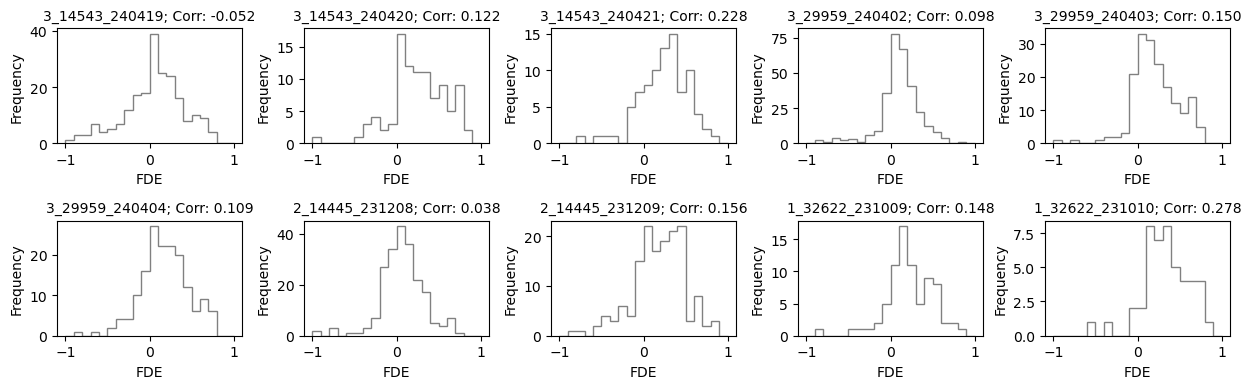

In [31]:
print(f"Median of FDE for in-domain flights: {np.nanmedian(np.hstack([fde_indomain_dict[session_name] for session_name in list(dataloaders['test'].keys())]))}")
ncols = 5
nrows = len(list(dataloaders['test'].keys())) // ncols
fig, axes = plt.subplots(nrows=nrows, ncols=ncols,figsize=(ncols*2.5,nrows*2))
for ii in range(nrows):
    for jj in range(ncols):
        session_name = list(dataloaders['test'].keys()) [ii * ncols + jj]
        data = np.copy(fde_indomain_dict[session_name])
        hist_max = 1.0 # np.max(data)
        hist_min = -1.0 # np.min(data)
        weights = np.ones_like(data) # /float(len(data))
        axes[ii,jj].hist(data, bins=20, color='gray',range=[hist_min,hist_max],weights=weights,alpha=1,histtype='step')
        axes[ii,jj].set_xlabel('FDE')
        axes[ii,jj].set_ylabel('Frequency')
        axes[ii,jj].set_title(f'{session_name[8:]}; Corr: {np.nanmedian(data):.3f}', fontsize=10)
plt.tight_layout()

## Corr. vs. FDE

In [32]:
# Corr. vs. FDE
if False:
    ncols = 5
    nrows = len(list(dataloaders['test'].keys())) // ncols
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols,figsize=(ncols*2.5,nrows*2))
    for ii in range(nrows):
        for jj in range(ncols):
            session_name = list(dataloaders['test'].keys()) [ii * ncols + jj]
            axes[ii,jj].scatter(corr_dict[session_name], fde_dict[session_name], color='k', s=1)
            axes[ii,jj].set_ylim(-1.0, 1)
            axes[ii,jj].set_xlabel('Corr.')
            axes[ii,jj].set_ylabel('FDE')
            axes[ii,jj].set_title(f'{session_name[8:]}', fontsize=10)
    plt.tight_layout()

## Rate map

session_target: Dataset_3_29959_240403


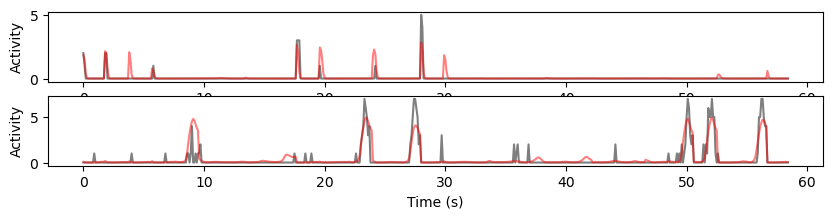

In [34]:
session_target = list(dataloaders['test'].keys())[4]
print(f'session_target: {session_target}')
bat_former.load_state_dict(torch.load(model_name, map_location=device))
# bat_former.load_state_dict(best_weights)
bat_former = bat_former.to(device)
bat_former.eval()
for session_name, session_data in dataloaders['test'].items():
    # print(session_name, session_data)
    if session_name == session_target:
        X_val_np_list = []
        y_val_np_list = []
        y_pred_np_list = []
        for batch_id, batch in enumerate(session_data):
            X_val = batch[0].to(device)
            y_val = batch[1].to(device)
            mask_val = batch[2].to(device)
            y_pred = bat_former(
                session_name, 
                X_val, 
                mask_val, 
                is_causal=trainer_config['is_causal'], 
                is_bigbird=trainer_config['is_bigbird'], 
                attention_window_size=trainer_config['attention_window_size'],
                num_global=trainer_config['num_global'],
            )
            X_val_np = X_val.detach()[mask_val == 1.0].cpu().numpy()
            y_val_np = y_val.detach()[mask_val == 1.0].cpu().numpy() 
            y_pred_np = y_pred.detach()[mask_val == 1.0].cpu().numpy()
            # print(f'X_val_np.shape: {X_val_np.shape}, y_val_np.shape: {y_val_np.shape}')
            X_val_np_list.append(X_val_np)
            y_val_np_list.append(y_val_np)
            y_pred_np_list.append(y_pred_np)
        X_val_np = np.vstack(X_val_np_list)
        y_val_np = np.vstack(y_val_np_list)
        y_pred_np = np.vstack(y_pred_np_list)
        # print(f'X_val_np.shape: {X_val_np.shape}, y_val_np.shape: {y_val_np.shape}')
        temp_scores = valid_fn(y_val_np, y_pred_np) # an array of scores for spiking units in one batch data within one session of data

ccs = np.copy(temp_scores)

temps = np.arange(-1, -3, -1).tolist() 
num = y_val_np.shape[0]
nrows = len(temps)
fig, ax = plt.subplots(nrows=nrows, ncols=1, figsize=(10, nrows))
for ii in range(nrows):
    temp = np.argsort(ccs)[temps[ii]]
    ax[ii].plot(np.arange(num) * data_config['bin_width'], y_val_np[:num, temp], color='k', alpha=0.5)
    ax[ii].plot(np.arange(num) * data_config['bin_width'], y_pred_np[:num,temp], color='red', alpha=0.5)
    ax[ii].set_xlabel("Time (s)") 
    ax[ii].set_ylabel("Activity")

In [36]:
print(f'session_target: {session_target}')
bat_former.load_state_dict(torch.load(model_name, map_location=device))
# bat_former.load_state_dict(best_weights)
bat_former = bat_former.to(device)
bat_former.eval()
for session_name, session_data in dataloaders['test'].items():
    # print(session_name, session_data)
    if session_name == session_target:
        X_val_np_list = []
        y_val_np_list = []
        y_pred_np_list = []
        mask_val_list = []
        flight_path_index_list = []
        flight_type_index_list = []
        for batch_id, batch in enumerate(session_data):
            X_val = batch.behavior.to(device)
            y_val = batch.spike.to(device)
            mask_val = batch.mask.to(device)
            y_pred = bat_former(
                session_name, 
                X_val, 
                mask_val, 
                is_causal=trainer_config['is_causal'], 
                is_bigbird=trainer_config['is_bigbird'], 
                attention_window_size=trainer_config['attention_window_size'],
                num_global=trainer_config['num_global'],
            )
            X_val_np = X_val.detach().cpu().numpy()
            y_val_np = y_val.detach().cpu().numpy() 
            y_pred_np = y_pred.detach().cpu().numpy()
            mask_val_np = mask_val.detach().cpu().numpy()
            flight_path_index_np = batch.flight_path_index.detach().cpu().numpy()
            flight_type_index_np = batch.flight_type_index.detach().cpu().numpy()
            #
            X_val_np_list.append(X_val_np)
            y_val_np_list.append(y_val_np)
            y_pred_np_list.append(y_pred_np)
            mask_val_list.append(mask_val_np)
            flight_path_index_list.append(flight_path_index_np)
            flight_type_index_list.append(flight_type_index_np)
X_val_np = np.vstack(X_val_np_list)
y_val_np = np.vstack(y_val_np_list)
y_pred_np = np.vstack(y_pred_np_list)
mask_val = np.vstack(mask_val_list)
flight_path_index = np.hstack(flight_path_index_list) # use hstack for stacking 1D arrays
flight_type_index = np.hstack(flight_type_index_list) # use hstack for stacking 1D arrays
print(f'X_val_np.shape: {X_val_np.shape}, y_val_np.shape: {y_val_np.shape}, y_pred_np.shape: {y_pred_np.shape}, mask_val.shape: {mask_val.shape}')
# X_val_np.shape: (64, 68, 3), y_val_np.shape: (64, 68, 168), y_pred_np.shape: (64, 68, 168), mask_val.shape: (64, 68),... 64 batches, 68 time points, 168 neurons
print(f'flight_path_index.shape: {flight_path_index.shape}, flight_type_index.shape: {flight_type_index.shape}') # flight_path_index.shape: (64,), flight_type_index.shape: (64,)
print(f'flight_path_index: {flight_path_index}')
print(f'flight_type_index: {flight_type_index}')

session_target: Dataset_3_29959_240403
X_val_np.shape: (21, 73, 3), y_val_np.shape: (21, 73, 191), y_pred_np.shape: (21, 73, 191), mask_val.shape: (21, 73)
flight_path_index.shape: (21,), flight_type_index.shape: (21,)
flight_path_index: [ 38.  34.  15.  36. 103.   0.  56.  11.  42.  84.  63.  10.  33. 125.
  68.  76.  81. 102.  93.  57.   5.]
flight_type_index: [ 3.  3.  3.  3. 27.  1. 13.  3.  3. 27. 17.  3.  3. 32. 17. 23. 25. 27.
 27. 14.  3.]


session_target: Dataset_3_29959_240403


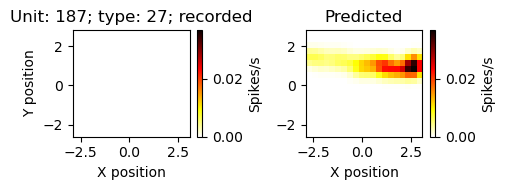

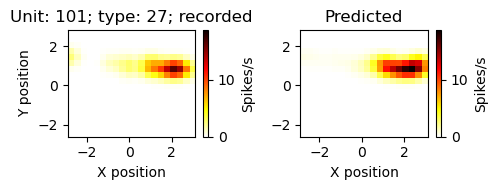

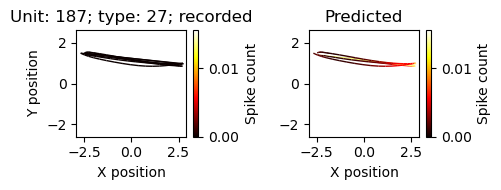

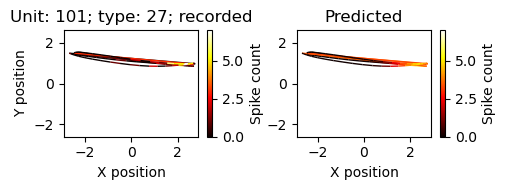

In [37]:
print(f'session_target: {session_target}')
target_type = 27
target_ind = np.where(flight_type_index == target_type)[0]
#
target_X_val = X_val_np[target_ind, :, :]
target_y_val = y_val_np[target_ind, :, :]
target_y_pred = y_pred_np[target_ind, :, :]
target_mask_val = mask_val[target_ind, ]
#
target_X_val = target_X_val[target_mask_val == 1.0]
target_y_val = target_y_val[target_mask_val == 1.0]
target_y_pred = target_y_pred[target_mask_val == 1.0]
# print(f'target_X_val.shape: {target_X_val.shape}, target_y_val.shape: {target_y_val.shape}, target_y_pred.shape: {target_y_pred.shape}')
# target_X_val.shape: (1512, 3), target_y_val.shape: (1512, 168), target_y_pred.shape: (1512, 168) # 168 neurons
loc_xx = target_X_val[:, 0] * meta_info_dict['behavior_std'][session_target][0, 0, 0] + meta_info_dict['behavior_mean'][session_target][0, 0, 0]
loc_yy = target_X_val[:, 1] * meta_info_dict['behavior_std'][session_target][0, 0, 1] + meta_info_dict['behavior_mean'][session_target][0, 0, 1]
loc_xx_lim = meta_info_dict['r_lim'][session_target][0, :]
loc_yy_lim = meta_info_dict['r_lim'][session_target][1, :]
loc_bin_width = 0.3 # the bin width for the location space
dt = np.copy(data_config['bin_width'])  # time interval for each data point (in seconds)
#
units = np.argsort(ccs)[-2:][::-1]
for unit in units:
    spike_count_val = target_y_val[:, unit]
    spike_count_pred = target_y_pred[:, unit]
    plot_2d_rate_map(
        unit=unit,
        target_type=target_type,
        loc_xx=loc_xx,
        loc_yy=loc_yy,
        spike_count_val=spike_count_val,
        spike_count_pred=spike_count_pred,
        loc_xx_lim=loc_xx_lim,
        loc_yy_lim=loc_yy_lim,
        loc_bin_width=loc_bin_width,
        dt=dt,
    )
for unit in units:
    spike_count_val = target_y_val[:, unit]
    spike_count_pred = target_y_pred[:, unit]
    plot_2d_trajectory_response(
        unit=unit,
        target_type=target_type,
        loc_xx=loc_xx,
        loc_yy=loc_yy,
        spike_count_val=spike_count_val,
        spike_count_pred=spike_count_pred,
        loc_xx_lim=loc_xx_lim,
        loc_yy_lim=loc_yy_lim,
    )

# Attention matrix

session_target: Dataset_3_29959_240403


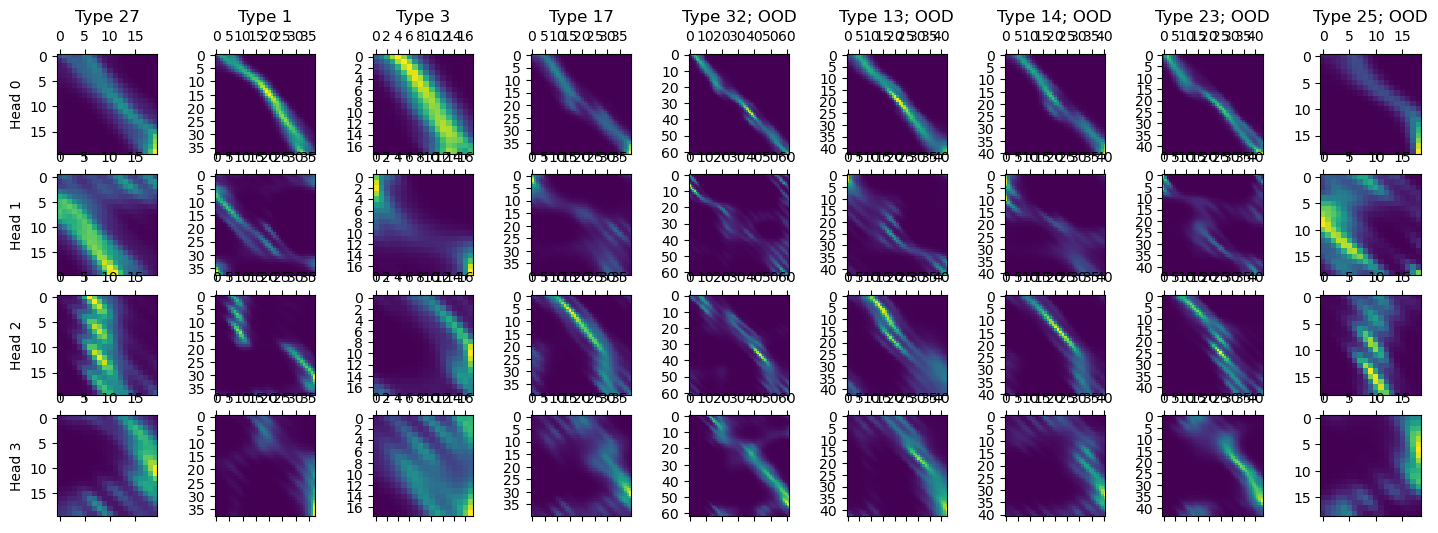

In [38]:
# Show attention weights for each flight cluster type within test data
session_target = list(dataloaders['test'].keys())[4]
print(f'session_target: {session_target}')
bat_former.load_state_dict(torch.load(model_name, map_location=device))
# bat_former.load_state_dict(best_weights)
bat_former = bat_former.to(device)
bat_former.eval()
for session_name, session_data in dataloaders['test'].items():
    # print(session_name, session_data)
    if session_name == session_target:
        # we have only one batch of test data
        for batch_id, batch in enumerate(session_data):
            X_val = batch[0].to(device)
            y_val = batch[1].to(device)
            mask_val = batch[2].to(device)
            flight_type_index = batch.flight_type_index.detach().cpu().numpy()
            y_pred, attn_weights_list = bat_former(
                session_name, 
                X_val, 
                mask_val, 
                is_causal=trainer_config['is_causal'], 
                is_bigbird=trainer_config['is_bigbird'], 
                attention_window_size=trainer_config['attention_window_size'],
                num_global=trainer_config['num_global'],
                return_attn_weights=True,
            )
            X_val_np = X_val.detach().cpu().numpy()
            mask_val_np = mask_val.detach().cpu().numpy()
attn_weights_list = [attn_weights.detach().cpu().numpy() for attn_weights in attn_weights_list]
target_types_indomain = np.array(meta_info_dict['flight_type_test_indomain'][session_target], dtype=int)
target_types_ood = np.array(meta_info_dict['flight_type_test_ood'][session_target], dtype=int)
target_types = np.concatenate((target_types_indomain, target_types_ood))

if True:
    nrows = attn_weights_list[0].shape[1]
    ncols = len(target_types_indomain) + len(target_types_ood)
    np.random.seed(1000)
    fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*2, nrows*1.5))
    for ii in range(nrows):
        for jj in range(ncols):
            batch_ind, head_ind = np.where(flight_type_index == target_types[jj])[0][0], ii
            # only show the unmask elements (not padding ones)
            unmask_T = int(np.sum(mask_val.detach().cpu().numpy(), axis=1)[batch_ind])
            # plt.imshow(attn_weights_list[0][10,1])
            ax[ii,jj].matshow(attn_weights_list[0][batch_ind, head_ind][:unmask_T, :unmask_T])
        ax[ii,0].set_ylabel(f'Head {ii}')
    for jj in range(ncols):
        ax[0,jj].set_title(f'Type {target_types[jj]}' if target_types[jj] in target_types_indomain else f'Type {target_types[jj]}; OOD')

session_target: Dataset_3_29959_240403


Text(0, 0.5, 'Importance')

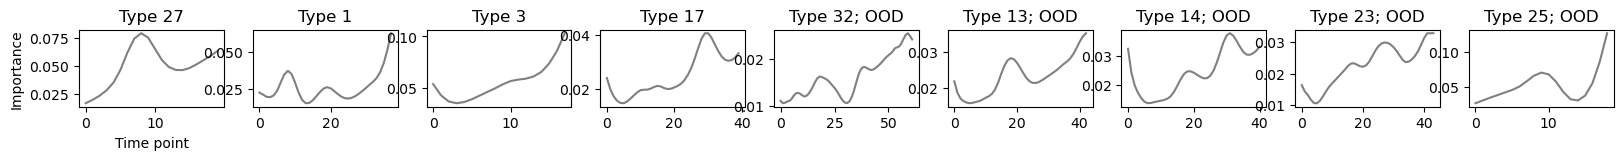

In [39]:
# For each attention matrix, we aggregate weights over the query axis and compute an importance score per time point
# that reflects its overall influence on the model's internal representation (i.e., how strongly the model attends to each position).
# we normalize the score by the length of the query (each flight path) and n_head
print(f'session_target: {session_target}')
ncols = len(target_types) 
nheads = attn_weights_list[0].shape[1] 
fig, ax = plt.subplots(nrows=1, ncols=ncols, figsize=(ncols*2.2, 1.0))
for ii in range(ncols): # for each flight cluster type
    inds = np.where(flight_type_index==target_types[ii])[0]
    temps = []
    for jj in range(1): # for each flight path: for jj in range(counts[ii]) # for now, we only use one flight path # TODO
        for kk in range(nheads): # for each attention head
            batch_ind, head_ind = inds[jj], kk
            # only show the unmask elements (not padding ones)
            unmask_T = int(np.sum(mask_val.detach().cpu().numpy(), axis=1)[batch_ind])
            temps.append(np.sum(attn_weights_list[0][batch_ind, head_ind][:unmask_T, :unmask_T], axis=0)/(unmask_T*nheads)) # sum across query
    temp = np.sum(np.array(temps), axis=0) # sum across heads and flight paths (belong to the same type)
    # ax[ii].bar(np.arange(len(temp)), temp, color='gray')
    ax[ii].plot(np.arange(len(temp)), temp, color='gray')
    ax[ii].set_title(f'Type {target_types[ii]}' if target_types[ii] in target_types_indomain else f'Type {target_types[ii]}; OOD')
ax[0].set_xlabel('Time point')
ax[0].set_ylabel('Importance')

session_target: Dataset_3_29959_240403


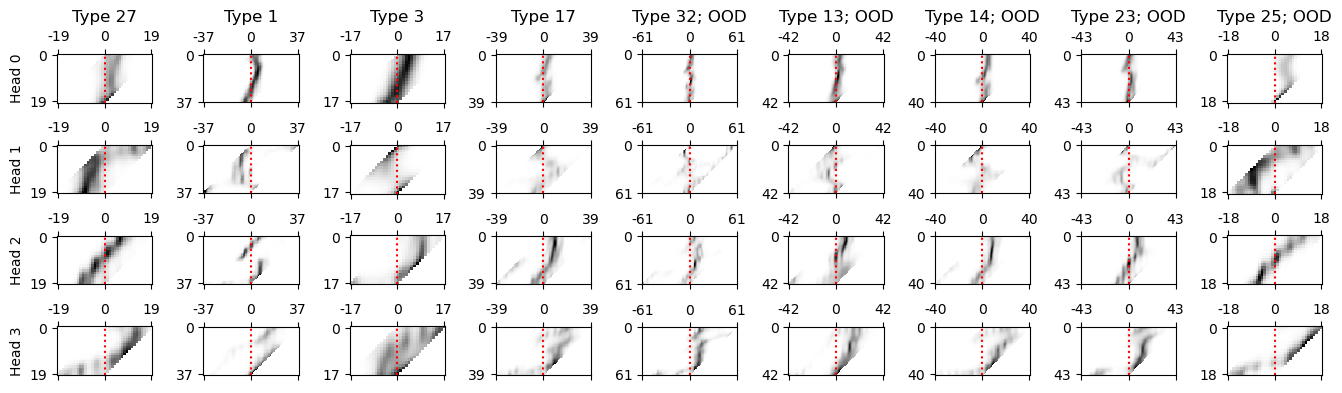

In [40]:
# For each time point, we reindex the attention matrix by a specific temporal offset relative to the query position, 
# producing a time-lag importance profile that quantifies how strongly each position attends to the past, present, and future. 
# This transformation enables direct comparison of temporal dependencies across all positions in the sequence.
from digitalbat.utility.utils import compute_shift_attention
print(f'session_target: {session_target}')
nrows = attn_weights_list[0].shape[1]
ncols = len(target_types)
np.random.seed(1000)
# batch_inds = np.where(flight_type_index==unique_flight_types[temp_ind])[0] # np.random.randint(0, attn_weights_list[0].shape[0], size = ncols)
fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*1.5, nrows*1))
for ii in range(nrows):
    for jj in range(ncols):
        batch_ind, head_ind = np.where(flight_type_index==target_types[jj])[0][0], ii
        # only show the unmask elements (not padding ones)
        unmask_T = int(np.sum(mask_val.detach().cpu().numpy(), axis=1)[batch_ind])
        # plt.imshow(attn_weights_list[0][10,1])
        shift_attn = compute_shift_attention(attn_weights_list[0][batch_ind, head_ind][:unmask_T, :unmask_T])
        # ax[ii,jj].imshow(np.log10(shift_attn+1e-7), cmap='gray_r')
        ax[ii,jj].matshow(shift_attn, cmap='gray_r')
        ax[ii,jj].axvline(unmask_T-1, color='red', linestyle=':')
        ax[ii,jj].set_yticks([0, shift_attn.shape[0]-1])
        ax[ii,jj].set_xticks([0, unmask_T-1, shift_attn.shape[1]-1])
        ax[ii,jj].set_xticklabels([-(unmask_T-1), 0, unmask_T-1])
    ax[ii,0].set_ylabel(f'Head {ii}')
for jj in range(ncols):
    ax[0,jj].set_title(f'Type {target_types[jj]}' if target_types[jj] in target_types_indomain else f'Type {target_types[jj]}; OOD')
plt.tight_layout()

session_target: Dataset_3_29959_240403


Text(0, 0.5, 'Importance')

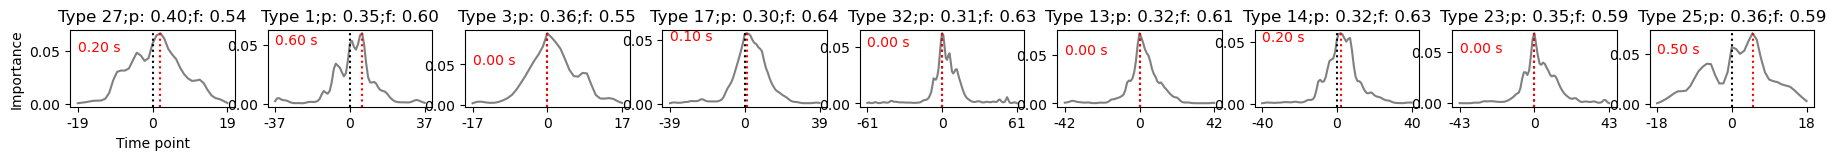

In [41]:
# For each shift attention matrix, we aggregate weights over the query axis and compute an importance score per time point
print(f'session_target: {session_target}')
ncols = len(target_types) 
nheads = attn_weights_list[0].shape[1] 
fig, ax = plt.subplots(nrows=1, ncols=ncols, figsize=(ncols*2.5, 1.0))
for ii in range(ncols): # for each flight cluster type
    inds = np.where(flight_type_index==target_types[ii])[0]
    temps = []
    for jj in range(1): # for each flight path: for jj in range(counts[ii]) # for now, we only use one flight path # TODO
        for kk in range(nheads): # for each attention head
            batch_ind, head_ind = inds[jj], kk
            # only show the unmask elements (not padding ones)
            unmask_T = int(np.sum(mask_val.detach().cpu().numpy(), axis=1)[batch_ind])
            shift_attn = compute_shift_attention(attn_weights_list[0][batch_ind, head_ind][:unmask_T, :unmask_T])
            temps.append(np.sum(shift_attn, axis=0)/(unmask_T*nheads)) # sum across query
    temp = np.sum(np.array(temps), axis=0) # sum across heads and flight paths (belong to the same type)
    # ax[ii].bar(np.arange(len(temp)), temp, color='gray')
    ax[ii].plot(np.arange(len(temp)), temp, color='gray')
    ax[ii].axvline(unmask_T-1, color='k', linestyle=':')
    ax[ii].axvline(np.argmax(temp), color='red', linestyle=':')
    ax[ii].text(0, 0.05, f"{(np.argmax(temp)-(unmask_T-1)) * data_config['bin_width']:.2f} s", color='red')
    ax[ii].set_xticks([0, unmask_T-1, shift_attn.shape[1]-1])
    ax[ii].set_xticklabels([-(unmask_T-1), 0, unmask_T-1])
    ax[ii].set_title(f'Type {target_types[ii]};p: {np.sum(temp[:unmask_T-1]):.2f};f: {np.sum(temp[unmask_T:]):.2f}')
ax[0].set_xlabel('Time point')
ax[0].set_ylabel('Importance')

session_target: Dataset_3_29959_240403


Text(0, 0.5, 'Query time')

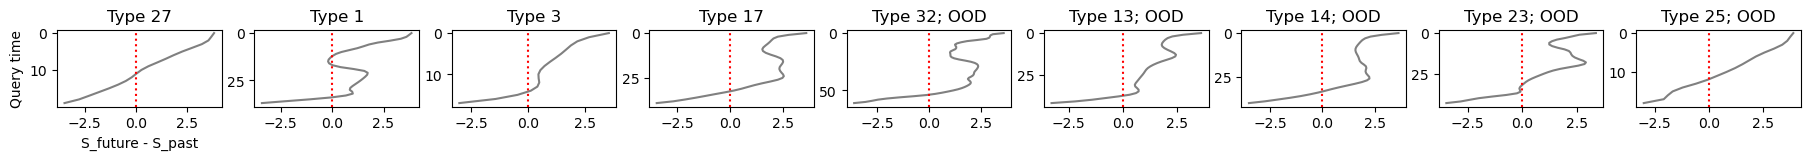

In [42]:
# For each (shift) attention, for each query time position, we aggregate scores over the key axis separately for the past and the future
# and then we subtract the past from the future. At the start of a flight, of course, it only attends to the future. The question is that
# when it starts to attend more to the past.
print(f'session_target: {session_target}')
ncols = len(target_types) 
nheads = attn_weights_list[0].shape[1] 
fig, ax = plt.subplots(nrows=1, ncols=ncols, figsize=(ncols*2.5, 1.0))
for ii in range(ncols): # for each flight cluster type
    inds = np.where(flight_type_index==target_types[ii])[0]
    temps = []
    for jj in range(1): # for each flight path: for jj in range(counts[ii]) # for now, we only use one flight path # TODO
        for kk in range(nheads): # for each attention head
            batch_ind, head_ind = inds[jj], kk
            # only show the unmask elements (not padding ones)
            unmask_T = int(np.sum(mask_val.detach().cpu().numpy(), axis=1)[batch_ind])
            shift_attn = compute_shift_attention(attn_weights_list[0][batch_ind, head_ind][:unmask_T, :unmask_T])
            temps.append(np.sum(shift_attn[:,unmask_T:],axis=1) - np.sum(shift_attn[:,:unmask_T-1], axis=1)) # (future - past) for each query time position 
    temp = np.sum(np.array(temps), axis=0) # sum across heads and flight paths (belong to the same type)
    # ax[ii].barh(np.arange(len(temp)), temp, color='gray')
    ax[ii].plot(temp, np.arange(len(temp)), color='gray')
    ax[ii].invert_yaxis()
    ax[ii].axvline(0.0, color='red', linestyle=':')
    ax[ii].set_title(f'Type {target_types[ii]}' if target_types[ii] in target_types_indomain else f'Type {target_types[ii]}; OOD')
ax[0].set_xlabel('S_future - S_past')
ax[0].set_ylabel('Query time')

session_target: Dataset_3_29959_240403


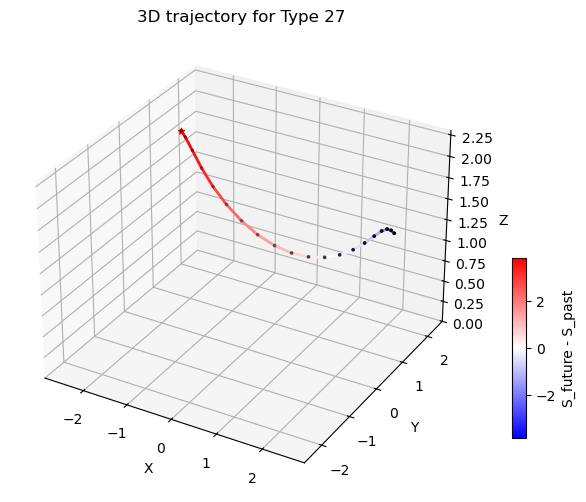

In [43]:
# Plot the 3d trajectory of one flight path (from each flight cluster type), colorized by S_future - S_past 
print(f'session_target: {session_target}')
nheads = attn_weights_list[0].shape[1] # attn_weights_list[0].shape: (64, 4, 68, 68) (batch_size, nheads, T, T)
for ii in range(1): # for ii in range(len(target_types)); for ii in range(1)
    inds = np.where(flight_type_index==target_types[ii])[0]
    for jj in range(1): # for flight paths belong to that type: for jj in range(len(inds)) # for now, we only use one flight path # TODO
        batch_ind = inds[jj]
        temps = []
        for kk in range(nheads): # for each attention head
            # only show the unmask elements (not padding ones)
            unmask_T = int(np.sum(mask_val_np, axis=1)[batch_ind]) # mask_val_np.shape: (64, 68) (batch_size, T)
            shift_attn = compute_shift_attention(attn_weights_list[0][batch_ind, kk][:unmask_T, :unmask_T])
            temps.append(np.sum(shift_attn[:,unmask_T:],axis=1) - np.sum(shift_attn[:,:unmask_T-1], axis=1)) # (future - past) for each query time position 
        s_fut_past = np.sum(np.array(temps), axis=0) # sum across heads 
    
        plot_config = dict(
            # X_val_np.shape: (64, 68, 3) (batch_size, T, 3)
            trajectory_3d = X_val_np[batch_ind][mask_val_np[batch_ind]==1.0,:] * meta_info_dict['behavior_std'][session_target][0,:,:] + meta_info_dict['behavior_mean'][session_target][0,:,:], 
            loc_lim = meta_info_dict['r_lim'][session_target], 
            flight_cluster_type = int(flight_type_index[batch_ind]),
            time_bin_width = data_config['bin_width'],
            visualize_array = s_fut_past, 
            cmap = 'bwr', 
            set_zero_as_medium = True,
            cax_ylabel = 'S_future - S_past', # colorbar ylabel
        )
        plot_3d_trajectory(
            **plot_config
        )

# Saliency

session_target: Dataset_3_29959_240403; target_neuron_index: 20; target_flight_type: 14


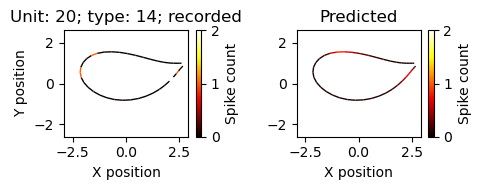

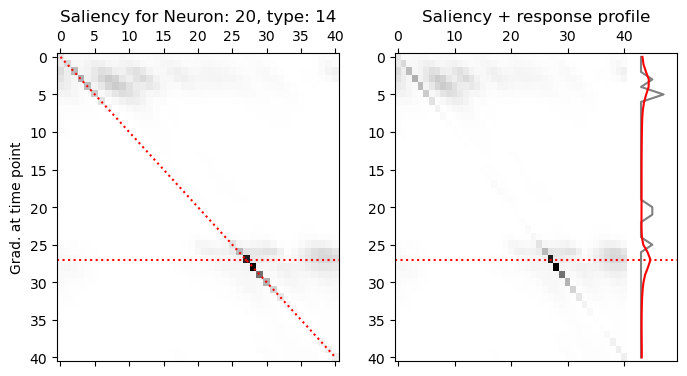

In [45]:
session_target = list(dataloaders['test'].keys())[4] # [4]
target_neuron_index = 20 # 139 # 177
# get the input (flight path) and its mask
target_flight_type = 14 # 32, 23
print(f'session_target: {session_target}; target_neuron_index: {target_neuron_index}; target_flight_type: {target_flight_type}')
for session_name, session_data in dataloaders['test'].items():
    # print(session_name, session_data)
    if session_name == session_target:
        # we have only one batch of test data
        for batch_id, batch in enumerate(session_data):
            X_val = batch[0].to(device)
            y_val = batch[1].to(device)
            mask_val = batch[2].to(device)
            flight_type_index = batch.flight_type_index.detach().cpu().numpy()
            target_flight_index = int(np.where(flight_type_index == target_flight_type)[0][0])
X_val = X_val[target_flight_index][None, :, :]
y_val = y_val[target_flight_index][None, :, :]
mask_val = mask_val[target_flight_index][None, :]
# model
bat_former.load_state_dict(torch.load(model_name, map_location=device))
# bat_former.load_state_dict(best_weights)
bat_former = bat_former.to(device)
bat_former.eval()
# compute gradient
grad_bat_former = Gradient_Bat_Transformer(
    model = bat_former,
    session_name = session_target, 
    X_val = X_val, # flight path; (torch.Size([1, num_of_time_points, 3]),
    y_val = y_val, # (torch.Size([1, num_of_time_points, num_of_neurons])
    mask_val = mask_val, # mask for the path; torch.Size([1, num_of_time_points]))
    target_neuron_index = target_neuron_index,
    trainer_config = trainer_config,
    device = device,
)
grad_bat_former.compute_feature_importance()

target_X_val = grad_bat_former.flight_path
loc_xx = target_X_val[:, 0] * meta_info_dict['behavior_std'][session_target][0, 0, 0] + meta_info_dict['behavior_mean'][session_target][0, 0, 0]
loc_yy = target_X_val[:, 1] * meta_info_dict['behavior_std'][session_target][0, 0, 1] + meta_info_dict['behavior_mean'][session_target][0, 0, 1]
loc_xx_lim = meta_info_dict['r_lim'][session_target][0, :]
loc_yy_lim = meta_info_dict['r_lim'][session_target][1, :]
spike_count_val = grad_bat_former.response_val
spike_count_pred = grad_bat_former.response_pred
plot_2d_trajectory_response(
    unit=target_neuron_index,
    target_type=target_flight_type,
    loc_xx=loc_xx,
    loc_yy=loc_yy,
    spike_count_val=spike_count_val,
    spike_count_pred=spike_count_pred,
    loc_xx_lim=loc_xx_lim,
    loc_yy_lim=loc_yy_lim,
)

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(8,4))
axs[0].matshow(np.linalg.norm(np.array(grad_bat_former.gradient_list), axis=2), cmap='gray_r', aspect='auto')
axs[0].axhline(y = np.argmax(grad_bat_former.response_pred), color='red', linestyle=':')
# plt.plot((grad_bat_former.unmask_T, grad_bat_former.unmask_T), (0, grad_bat_former.unmask_T), color='red', linestyle=':')
axs[0].plot((0, grad_bat_former.unmask_T-1), (0, grad_bat_former.unmask_T-1), color='red', linestyle=':')
axs[0].set_title(f'Saliency for Neuron: {target_neuron_index}, type: {target_flight_type}')
axs[0].set_ylabel('Grad. at time point')

axs[1].matshow(np.linalg.norm(np.array(grad_bat_former.gradient_list), axis=2), cmap='gray_r', aspect='auto')
axs[1].axhline(y = np.argmax(grad_bat_former.response_pred), color='red', linestyle=':')
# axs[1].plot((0, grad_bat_former.unmask_T-1), (0, grad_bat_former.unmask_T-1), color='red', linestyle=':')
axs[1].set_title(f'Saliency + response profile')
axs[1].plot(grad_bat_former.response_val * 2 + grad_bat_former.unmask_T + 2, np.arange(grad_bat_former.unmask_T), color='gray')
axs[1].plot(grad_bat_former.response_pred * 2 + grad_bat_former.unmask_T + 2, np.arange(grad_bat_former.unmask_T), color='r')

Saliency + response profile: session_target: Dataset_3_29959_240403, target_flight_type: 14


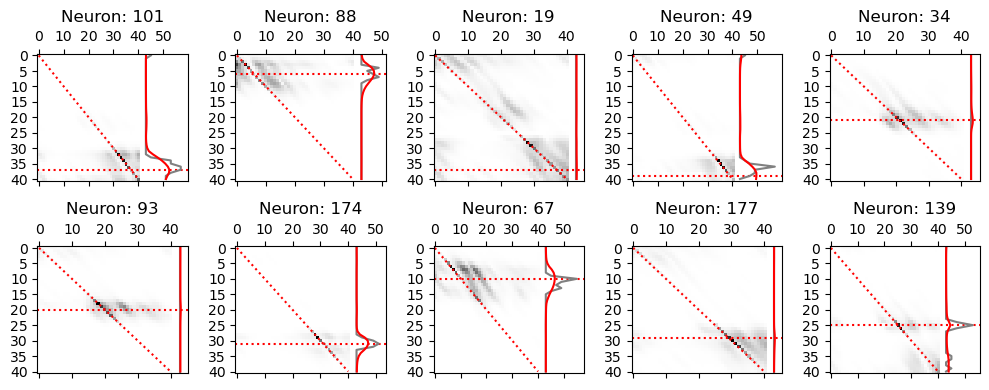

In [47]:
# Show saliency and reponse profiles for multiple neurons during the same flight path
target_flight_type = 14 # 25 # 32, 23
print(f'Saliency + response profile: session_target: {session_target}, target_flight_type: {target_flight_type}')
target_neuron_indices = np.argsort(corr_ood_dict[session_target])[::-1][:10]
ncols = 5
nrows = int(len(target_neuron_indices)/ncols)
fig, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*2, nrows*2))
for ii in range(nrows):
    for jj in range(ncols):
        target_neuron_index = target_neuron_indices[ii*ncols+jj]

        # get the input (flight path) and its mask
        for session_name, session_data in dataloaders['test'].items():
            # print(session_name, session_data)
            if session_name == session_target:
                # we have only one batch of test data
                for batch_id, batch in enumerate(session_data):
                    X_val = batch[0].to(device)
                    y_val = batch[1].to(device)
                    mask_val = batch[2].to(device)
                    flight_type_index = batch.flight_type_index.detach().cpu().numpy()
                    target_flight_index = int(np.where(flight_type_index == target_flight_type)[0][0])
        X_val = X_val[target_flight_index][None, :, :]
        y_val = y_val[target_flight_index][None, :, :]
        mask_val = mask_val[target_flight_index][None, :]
        # model
        bat_former.load_state_dict(torch.load(model_name, map_location=device))
        # bat_former.load_state_dict(best_weights)
        bat_former = bat_former.to(device)
        bat_former.eval()
        # compute gradient
        grad_bat_former = Gradient_Bat_Transformer(
            model = bat_former,
            session_name = session_target, 
            X_val = X_val, # flight path; (torch.Size([1, num_of_time_points, 3]),
            y_val = y_val, # (torch.Size([1, num_of_time_points, num_of_neurons])
            mask_val = mask_val, # mask for the path; torch.Size([1, num_of_time_points]))
            target_neuron_index = target_neuron_index,
            trainer_config = trainer_config,
            device = device,
        )
        grad_bat_former.compute_feature_importance()
        
        axs[ii,jj].matshow(np.linalg.norm(np.array(grad_bat_former.gradient_list), axis=2), cmap='gray_r', aspect='auto')
        axs[ii,jj].axhline(y = np.argmax(grad_bat_former.response_pred), color='red', linestyle=':')
        axs[ii,jj].plot((0, grad_bat_former.unmask_T-1), (0, grad_bat_former.unmask_T-1), color='red', linestyle=':')
        axs[ii,jj].set_title(f'Neuron: {target_neuron_index}')
        axs[ii,jj].plot(grad_bat_former.response_val * 2 + grad_bat_former.unmask_T + 2, np.arange(grad_bat_former.unmask_T), color='gray')
        axs[ii,jj].plot(grad_bat_former.response_pred * 2 + grad_bat_former.unmask_T + 2, np.arange(grad_bat_former.unmask_T), color='r')
plt.tight_layout()

# Hierarchical clustering and orthogonality test

## Quick test

In [48]:
session_target = list(dataloaders['test'].keys())[4] # [4]
bat_former.load_state_dict(torch.load(model_name, map_location=device))
# bat_former.load_state_dict(best_weights)
bat_former = bat_former.to(device)
bat_former.eval()
readout_weights = bat_former.readouts[session_target][0].weight.detach().cpu().numpy()
print(f'session_target: {session_target}, readout_weights.shape: {readout_weights.shape}')

session_target: Dataset_3_29959_240403, readout_weights.shape: (191, 32)


In [49]:
thresh = 0.4
inds = np.where(corr_ood_dict[session_target] > thresh)[0]
# print(readout_weights[inds, :].shape)
weight_sim = cosine_similarity(readout_weights[inds, :])
print(f'weight_sim.shape: {weight_sim.shape}')

weight_sim.shape: (34, 34)


In [50]:
print(inds[np.where(np.abs(weight_sim)<0.001)[0]])
print(inds[np.where(np.abs(weight_sim)<0.001)[1]])
# plt.matshow(weight_sim, vmin=weight_sim.min(), vmax=-weight_sim.min(),cmap='bwr')
# plt.colorbar()

[ 49  62  68  68 127 137 179 180]
[137 180 127 179  68  49  68  62]


## Analysis

In [51]:
thresh = 0.3
inds_sessions = {} # a dictionary of neuronal indices for each session
readout_weight_sessions = [] # readout weights for selected units from all sessions
for session_target in list(dataloaders['test'].keys()):
    bat_former.load_state_dict(torch.load(model_name, map_location=device))
    bat_former = bat_former.to(device)
    bat_former.eval()
    readout_weights = bat_former.readouts[session_target][0].weight.detach().cpu().numpy()
    inds = np.where(corr_ood_dict[session_target] > thresh)[0]
    inds_sessions[session_target] = inds
    readout_weight_sessions.append(readout_weights[inds, :])
readout_weight_sessions = np.vstack(readout_weight_sessions)
# print(inds_sessions)
print(f'readout_weight_sessions.shape: {readout_weight_sessions.shape}') # (363, 256): 363 units, 256 features, aligned with inds_sessions_df rows

inds_sessions_df = pd.concat(
    [
        pd.DataFrame({
            "session_neuron_idx": inds,
            "session_name": session
        })
        for session, inds in inds_sessions.items()
    ],
    ignore_index=True
)
inds_sessions_df["global_neuron_idx"] = range(len(inds_sessions_df)) # a dataframe contains session_neuron_idx, session_name and global_neuron_idx
print(inds_sessions_df)

readout_weight_sessions.shape: (381, 32)
     session_neuron_idx            session_name  global_neuron_idx
0                     0  Dataset_3_14543_240419                  0
1                     1  Dataset_3_14543_240419                  1
2                     2  Dataset_3_14543_240419                  2
3                     7  Dataset_3_14543_240419                  3
4                    40  Dataset_3_14543_240419                  4
..                  ...                     ...                ...
376                  35  Dataset_1_32622_231010                376
377                  41  Dataset_1_32622_231010                377
378                  46  Dataset_1_32622_231010                378
379                  50  Dataset_1_32622_231010                379
380                  53  Dataset_1_32622_231010                380

[381 rows x 3 columns]


In [52]:
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.cluster.hierarchy import fcluster

X = np.copy(readout_weight_sessions)
X = X / np.linalg.norm(X, axis=1, keepdims=True)
# cosine distance = 1 - cosine similarity
dist_condensed = pdist(X, metric="cosine") # shape (363 * 362 / 2,)
dist_matrix = squareform(dist_condensed)  # shape (363, 363)
# Hierarchical clustering
Z = linkage(dist_condensed, method="average")
# The dendrogram returns the leaf order that optimally reflects the hierarchy
dendro = dendrogram(Z, no_plot=True)
order = dendro["leaves"]  # list of reordered neuron indices
# Reorder the distance matrix
dist_matrix_reordered = dist_matrix[np.ix_(order, order)]

In [53]:
# plt.figure(figsize=(7, 7))
# im = plt.imshow(dist_matrix_reordered, origin="lower")
# plt.colorbar(im, label="Cosine distance")
# plt.title("Reordered cosine distance matrix (hierarchical clustering)")
# plt.xlabel("Neuron (reordered)")
# plt.ylabel("Neuron (reordered)")
# plt.tight_layout()

Failed to reload module 'numpy.linalg' from file '/home/adam/miniconda3/envs/cpu/lib/python3.11/site-packages/numpy/linalg/__init__.py'
Traceback (most recent call last):
  File "/home/adam/miniconda3/envs/cpu/lib/python3.11/site-packages/IPython/extensions/autoreload.py", line 325, in check
    superreload(m, reload, self.old_objects)
  File "/home/adam/miniconda3/envs/cpu/lib/python3.11/site-packages/IPython/extensions/autoreload.py", line 584, in superreload
    module = reload(module)
             ^^^^^^^^^^^^^^
  File "/home/adam/miniconda3/envs/cpu/lib/python3.11/importlib/__init__.py", line 169, in reload
    _bootstrap._exec(spec, module)
  File "<frozen importlib._bootstrap>", line 621, in _exec
  File "<frozen importlib._bootstrap_external>", line 940, in exec_module
  File "<frozen importlib._bootstrap>", line 241, in _call_with_frames_removed
  File "/home/adam/miniconda3/envs/cpu/lib/python3.11/site-packages/numpy/linalg/__init__.py", line 73, in <module>
    from . import

In [54]:
# # plot dendrogram and reordered distance matrix
# fig = plt.figure(figsize=(7, 5))
# # Dendrogram
# ax_dendro = fig.add_axes([0.09, 0.1, 0.2, 0.8])
# dendrogram(
#     Z,
#     orientation="left",
#     # truncate_mode="level",
#     # p=4,                  # show only 4 levels
#     no_labels=True,
#     ax=ax_dendro
# )
# ax_dendro.set_xticks([])
# ax_dendro.set_yticks([])
# # Distance matrix (reordered)
# ax_mat = fig.add_axes([0.3, 0.1, 0.6, 0.8])
# im = ax_mat.matshow(dist_matrix_reordered, aspect="auto", origin="lower")
# ax_mat.set_xticks([])
# ax_mat.set_yticks([])
# # Colorbar
# ax_cb = fig.add_axes([0.92, 0.1, 0.02, 0.8])
# plt.colorbar(im, cax=ax_cb, label="Cosine distance")

In [55]:
# merge_distances = Z[:, 2]
# plt.figure(figsize=(5, 3))
# plt.plot(np.sort(merge_distances)[::-1])
# plt.xlabel("Merge step (largest → smallest)")
# plt.ylabel("Cosine distance")
# plt.title("Hierarchy merge distances")
# plt.tight_layout()

for t in [0.6, 0.7, 0.8, 0.9]:
    n = len(np.unique(fcluster(Z, t, criterion="distance")))
    print(f"t={t}: {n} clusters")

AttributeError: module 'numpy._core.multiarray' has no attribute 'ndarray'

Text(0.5, 1.0, 'Cluster sizes (t = 0.9)')

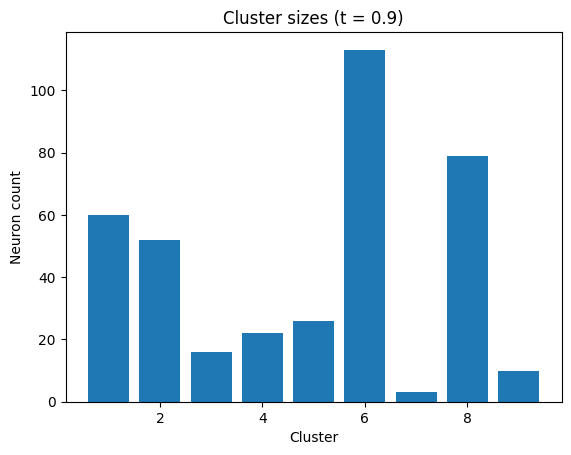

In [ ]:
labels = fcluster(Z, 0.9, criterion="distance")
unique, counts = np.unique(labels, return_counts=True)

plt.bar(unique, counts)
plt.xlabel("Cluster")
plt.ylabel("Neuron count")
plt.title("Cluster sizes (t = 0.9)")

Text(0.5, 1.0, 'Cluster composition across sessions')

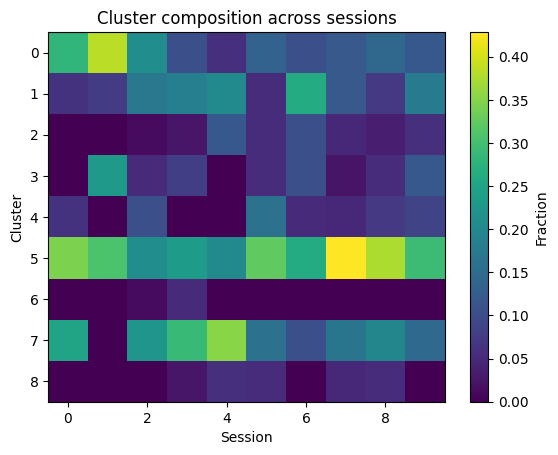

In [ ]:
inds_sessions_df["cluster"] = labels
ct = pd.crosstab(inds_sessions_df["cluster"], inds_sessions_df["session_name"], normalize="columns")

plt.imshow(ct, aspect="auto")
plt.colorbar(label="Fraction")
plt.xlabel("Session")
plt.ylabel("Cluster")
plt.title("Cluster composition across sessions")

In [ ]:
# Reorder neuron metadata
inds_sessions_df_reordered = inds_sessions_df.iloc[order].reset_index(drop=True)
inds_sessions_df_reordered

,session_neuron_idx,session_name,global_neuron_idx,cluster
0,23,Dataset_1_32622_231010,374,1
1,124,Dataset_3_14543_240420,70,1
2,253,Dataset_3_29959_240402,124,1
3,146,Dataset_3_29959_240403,175,1
4,189,Dataset_2_14445_231208,281,1
...,...,...,...,...
376,6,Dataset_3_14543_240420,36,9
377,282,Dataset_3_14543_240419,32,9
378,1,Dataset_3_14543_240420,35,9
379,243,Dataset_3_29959_240402,123,9


In [ ]:
tester = OrthogonalityPermutationTest(
    X=readout_weight_sessions,
    df=inds_sessions_df,
    session_name=list(dataloaders['test'].keys())[4],
    n_perm=1000,
    random_state=0,
    null_model='shuffle_weights',
)
sig_df = tester.significant_pairs_with_session_indices(alpha=0.05)
sig_df

,session_neuron_idx_1,session_neuron_idx_2,p_value,cosine_distance
0,1,11,0.032967,0.992868
1,2,51,0.039960,0.990459
2,2,68,0.021978,1.004433
3,5,34,0.043956,0.986578
4,6,179,0.019980,0.996205
...,...,...,...,...
56,138,139,0.029970,0.992463
57,139,186,0.013986,0.996778
58,151,161,0.019980,1.003590
59,151,180,0.025974,1.005112


In [ ]:
sig_df[sig_df['session_neuron_idx_1'] == 20]

,session_neuron_idx_1,session_neuron_idx_2,p_value,cosine_distance
12,20,88,0.028971,1.007233
13,20,117,0.008991,0.998414
14,20,128,0.006993,1.002309
15,20,137,0.042957,0.991724


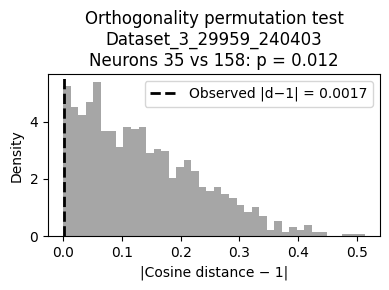

In [ ]:
row = sig_df.iloc[21]
tester.plot_null_vs_observed(
    session_neuron_idx_1=row["session_neuron_idx_1"],
    session_neuron_idx_2=row["session_neuron_idx_2"],
)

# GLM model with 3D cosine basis

In [ ]:
from digitalbat.models.glm import Bat_GLM


def create_cosine_bumps_torch(x, centers, width):
    """Raised cosine bumps in PyTorch.

    x: (...,) tensor of positions
    centers: (K,) tensor of bump centers
    width: scalar bump width

    returns: (..., K) tensor
    """
    diff = x.unsqueeze(-1) - centers
    return (torch.cos(2 * np.pi * diff / width) * 0.5 + 0.5) * (diff.abs() < width / 2).float()


class GLM_3DCosineBasis(nn.Module):
    """3D tensor-product cosine basis expansion + session-wise linear GLM.

    Equivalent to GLM_PyTorch but with session-wise heads, using 3D
    raised cosine bumps over (x, y, z) z-scored position as the design matrix.
    """
    def __init__(
        self,
        output_dim_dict,
        n_bases_per_dim=8,
        pos_range=(-3.0, 3.0),
        width_to_spacing_ratio=4,
        activation='exp',
    ):
        super().__init__()
        centers = torch.linspace(pos_range[0], pos_range[1], n_bases_per_dim)
        spacing = (pos_range[1] - pos_range[0]) / (n_bases_per_dim - 1)
        self.register_buffer('centers', centers)
        self.width = width_to_spacing_ratio * spacing
        self.n_bases_per_dim = n_bases_per_dim
        n_features = n_bases_per_dim ** 3
        self.glm = Bat_GLM(
            input_dim=n_features,
            output_dim_dict=output_dim_dict,
            activation=activation,
        )

    def forward(self, session_name, x, *args, **kwargs):
        # x: (N, T, behavior_dim) — first 3 dims = x, y, z (z-scored by dataloader)
        b_x = create_cosine_bumps_torch(x[..., 0], self.centers, self.width)  # (N, T, K)
        b_y = create_cosine_bumps_torch(x[..., 1], self.centers, self.width)
        b_z = create_cosine_bumps_torch(x[..., 2], self.centers, self.width)
        bases = (
            b_x.unsqueeze(-1).unsqueeze(-1)
            * b_y.unsqueeze(-2).unsqueeze(-1)
            * b_z.unsqueeze(-2).unsqueeze(-2)
        )  # (N, T, K, K, K)
        return self.glm(session_name, bases.flatten(-3))  # (N, T, K**3)


glm_config = dict(
    output_dim_dict=unit_num_dict,
    n_bases_per_dim=8,
    pos_range=(-3.0, 3.0),
    width_to_spacing_ratio=4,
    activation='exp',
)
bat_glm = GLM_3DCosineBasis(**glm_config)
bat_glm


### Visualize 3D cosine basis

In [ ]:
# Sanity check the 3D raised cosine basis used by the GLM.
# 1) 1D cosine bumps along one axis (should tile evenly — sum ≈ constant in interior).
# 2) A few selected 3D basis functions shown as 3D scatter (point size ∝ basis value).
# 3) Sum-of-bases slices (should be ~constant in the interior of the tiled cube).
# 4) Bases evaluated on real (z-scored) test positions.

centers = bat_glm.centers.cpu().numpy()
width = bat_glm.width
K = bat_glm.n_bases_per_dim
lo, hi = float(centers[0]), float(centers[-1])

# --- (1) 1D bumps along one axis ---
xs = torch.linspace(lo, hi, 500)
b1d = create_cosine_bumps_torch(xs, bat_glm.centers, width).cpu().numpy()
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(xs.numpy(), b1d)
axes[0].set(title=f'1D cosine bumps (K={K})', xlabel='z-score')
axes[1].plot(xs.numpy(), b1d.sum(axis=1), 'k')
axes[1].set(title='Sum of bumps (should be ~constant in interior)', xlabel='z-score')
plt.tight_layout()
plt.show()

# --- (2) Selected 3D basis functions over a 3D grid ---
N_GRID = 25
g = torch.linspace(lo, hi, N_GRID)
X3, Y3, Z3 = torch.meshgrid(g, g, g, indexing='ij')
grid = torch.stack([X3.flatten(), Y3.flatten(), Z3.flatten()], dim=-1)
bx = create_cosine_bumps_torch(grid[:, 0], bat_glm.centers, width)
by = create_cosine_bumps_torch(grid[:, 1], bat_glm.centers, width)
bz = create_cosine_bumps_torch(grid[:, 2], bat_glm.centers, width)
bases_grid = (bx.unsqueeze(-1).unsqueeze(-1) * by.unsqueeze(-2).unsqueeze(-1) * bz.unsqueeze(-2).unsqueeze(-2)).flatten(-3).cpu().numpy()

chosen = [
    (K // 2, K // 2, K // 2),
    (1, 1, 1),
    (K - 2, 1, K // 2),
    (K // 2, K - 2, 1),
]
fig = plt.figure(figsize=(14, 3.5))
for i, (ix, iy, iz) in enumerate(chosen):
    flat_idx = ix * K * K + iy * K + iz
    vals = bases_grid[:, flat_idx]
    keep = vals > 0.01
    ax = fig.add_subplot(1, 4, i + 1, projection='3d')
    ax.scatter(
        grid[keep, 0].cpu(), grid[keep, 1].cpu(), grid[keep, 2].cpu(),
        c=vals[keep], s=20 * vals[keep], cmap='viridis',
    )
    ax.set(title=f'basis ({ix},{iy},{iz})', xlim=(lo, hi), ylim=(lo, hi), zlim=(lo, hi))
plt.tight_layout()
plt.show()

# Sum-of-bases slices
total = bases_grid.sum(axis=1).reshape(N_GRID, N_GRID, N_GRID)
mid = N_GRID // 2
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, sl, name in zip(axes, [total[mid], total[:, mid], total[:, :, mid]], ['x=0', 'y=0', 'z=0']):
    im = ax.imshow(sl, extent=[lo, hi, lo, hi], origin='lower')
    ax.set_title(f'sum of bases (slice {name})')
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

# --- (3) Apply on real (z-scored) test positions ---
session_name = list(dataloaders['test'].keys())[0]
batch = next(iter(dataloaders['test'][session_name]))
X_real = batch[0]
mask_real = batch[2]
xyz = X_real[..., :3][mask_real == 1.0]
print(f"Real positions: shape={tuple(xyz.shape)}, "
      f"x∈[{xyz[:,0].min():.2f},{xyz[:,0].max():.2f}], "
      f"y∈[{xyz[:,1].min():.2f},{xyz[:,1].max():.2f}], "
      f"z∈[{xyz[:,2].min():.2f},{xyz[:,2].max():.2f}]")

with torch.no_grad():
    bx = create_cosine_bumps_torch(xyz[:, 0], bat_glm.centers, width)
    by = create_cosine_bumps_torch(xyz[:, 1], bat_glm.centers, width)
    bz = create_cosine_bumps_torch(xyz[:, 2], bat_glm.centers, width)
    bases_real = (bx.unsqueeze(-1).unsqueeze(-1) * by.unsqueeze(-2).unsqueeze(-1) * bz.unsqueeze(-2).unsqueeze(-2)).flatten(-3)

print(f"Bases on real data: per-sample sum mean={bases_real.sum(dim=1).mean():.3f} "
      f"(should be ~1 inside the tiled region), max={bases_real.max():.3f}")

fig, ax = plt.subplots(figsize=(10, 3))
im = ax.imshow(bases_real[:200].cpu().numpy().T, aspect='auto', cmap='viridis')
ax.set(xlabel='timepoint', ylabel='basis index',
       title=f'3D basis activations on real data ({K}^3 = {K**3} features)')
plt.colorbar(im, ax=ax, fraction=0.02)
plt.tight_layout()
plt.show()


## Training

In [ ]:
glm_trainer_config = dict(
    model=bat_glm,
    dataloaders=dataloaders,
    device=device,
    n_epochs=1000,
    lr=0.01,
    loss_fn=nn.PoissonNLLLoss(log_input=False),
    valid_fn=lambda y_true, y_pred: corr(y_true, y_pred, axis=0),
    valid_stat="mean",
    save_model=True,
    model_name=f"./out/bat_glm_3d_cosine_seed_{seed}.pth",
)

best_acc, best_weights, acc_vals = bat_former_trainer(**glm_trainer_config)
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(2.5, 2))
axes.plot(acc_vals)
axes.set_title(f"{best_acc:.4f}")
axes.set_xlabel("Epoch")
axes.set_ylabel("Correlation")


## Evaluation

### Correlation

In [ ]:
glm_model_name = f'./out/bat_glm_3d_cosine_seed_{seed}.pth'

# evaluation on test data
valid_fn = lambda y_true, y_pred: corr(y_true, y_pred, axis=0)
bat_glm.load_state_dict(torch.load(glm_model_name, map_location=device))
bat_glm = bat_glm.to(device)
bat_glm.eval()
glm_corr_dict = {}
for session_name, session_data in dataloaders['test'].items():
    y_val_np_list, y_pred_np_list = [], []
    for batch_id, batch in enumerate(session_data):
        X_val = batch[0].to(device)
        y_val = batch[1].to(device)
        mask_val = batch[2].to(device)
        y_pred = bat_glm(session_name, X_val, mask_val)
        y_val_np = y_val.detach()[mask_val == 1.0].cpu().numpy()
        y_pred_np = y_pred.detach()[mask_val == 1.0].cpu().numpy()
        y_val_np_list.append(y_val_np)
        y_pred_np_list.append(y_pred_np)
    y_val_np = np.vstack(y_val_np_list)
    y_pred_np = np.vstack(y_pred_np_list)
    glm_corr_dict[session_name] = valid_fn(y_val_np, y_pred_np)

print(f"Mean of Corr (GLM): {np.nanmean(np.hstack([glm_corr_dict[s] for s in list(dataloaders['test'].keys())]))}")


### Fraction deviance explained

In [ ]:
# evaluation on test data
valid_fn = lambda y_true, y_pred: poisson_fde_population(y_true, y_pred)
bat_glm.load_state_dict(torch.load(glm_model_name, map_location=device))
bat_glm = bat_glm.to(device)
bat_glm.eval()
glm_fde_dict = {}
for session_name, session_data in dataloaders['test'].items():
    y_val_np_list, y_pred_np_list = [], []
    for batch_id, batch in enumerate(session_data):
        X_val = batch[0].to(device)
        y_val = batch[1].to(device)
        mask_val = batch[2].to(device)
        y_pred = bat_glm(session_name, X_val, mask_val)
        y_val_np = y_val.detach()[mask_val == 1.0].cpu().numpy()
        y_pred_np = y_pred.detach()[mask_val == 1.0].cpu().numpy()
        y_val_np_list.append(y_val_np)
        y_pred_np_list.append(y_pred_np)
    y_val_np = np.vstack(y_val_np_list)
    y_pred_np = np.vstack(y_pred_np_list)
    glm_fde_dict[session_name] = valid_fn(y_val_np, y_pred_np)

print(f"Median of FDE (GLM): {np.nanmedian(np.hstack([glm_fde_dict[s] for s in list(dataloaders['test'].keys())]))}")
